In [1]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from matplotlib import font_manager
from matplotlib.lines import Line2D

plt.rcParams.update({
    "font.family": "Arial",
    "font.weight": "normal",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
})


In [2]:
import matplotlib.font_manager as fm
plt.rcParams["font.family"] = "Arial"
plt.rcParams["font.weight"] = "normal"
print([f.name for f in fm.fontManager.ttflist if "Arial" in f.name])

['Arial', 'Arial Rounded MT Bold', 'Arial', 'Arial', 'Arial', 'Arial', 'Arial', 'Arial', 'Arial', 'Arial']


Power: 11000
  LQR avg across RTR setpoints: 11005.841176470587
  FC-GPU avg across RTR setpoints: 11864.435006535947
  DFS avg across RTR setpoints: 10978.998823529411
Power: 11500
  LQR avg across RTR setpoints: 11497.04705882353
  FC-GPU avg across RTR setpoints: 11830.024705882353
  DFS avg across RTR setpoints: 11506.878823529412
Power: 12000
  LQR avg across RTR setpoints: 11999.258823529412
  FC-GPU avg across RTR setpoints: 11862.841176470589
  DFS avg across RTR setpoints: 11998.257647058823
Power: 12500
  LQR avg across RTR setpoints: 12496.649411764705
  FC-GPU avg across RTR setpoints: 11857.53294117647
  DFS avg across RTR setpoints: 12505.169411764706
Power: 13000
Missing: 02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_13000_0.75_0.75_0.75\FC_GPU_finalpowervalues.txt
  LQR avg across RTR setpoints: 12977.264705882353
  FC-GPU avg across RTR setpoints: 11891.625000000002
  DFS avg across RTR setpoints: 12986.343529411764


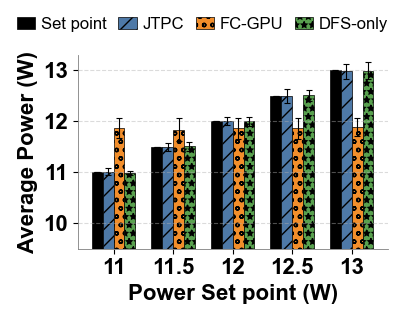

Saved plot to: figures\jetson_power_barplot.pdf
Saved plot to: figures\jetson_power_barplot.png


In [5]:
# LQR vs FC vs DFS Power Revision
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---------- FONT / STYLE ----------
plt.rcParams.update({
    "font.family": "Arial",
    "font.weight": "normal",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "axes.labelsize": 16,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ---------------- CONFIG ----------------
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 12

l_root = Path("02_regular_tests/logs/Full_LQR/hist_stereo_mm/")
f_root = Path("02_regular_tests/logs/Full_FC/hist_stereo_mm/")
d_root = Path("02_regular_tests/logs/Full_DFS/hist_stereo_mm/")

setpoints = [0.70, 0.75, 0.80, 0.85, 0.90]
power = [11000, 11500, 12000, 12500, 13000]  # mW in log folders
save_path = Path("figures")

colors = ["black", "#4E79A7", "#F28E2B", "#59A14F"]
hatches = ["", "//", "oo", "**"]
names = ["Set point", "JTPC", "FC-GPU", "DFS-only"]

# ---------------- HELPERS ----------------
def read_data(filepath: Path):
    if not filepath.exists():
        print(f"Missing: {filepath}")
        return np.array([])
    try:
        return np.loadtxt(filepath)
    except Exception as e:
        print(f"Error reading {filepath}: {e}")
        return np.array([])


def safe_slice(arr):
    if arr.size == 0:
        return arr
    return arr[100:-1] if arr.size > 101 else arr


def find_setpoint_dir(root: Path, sp1: float, sp2: int):
    candidates = [
        root / f"setpoint_{sp1:.2f}",
        root / f"setpoint_{sp2}_{sp1:.2f}_{sp1:.2f}_{sp1:.2f}",
        root / f"setpoint_{sp2}_0.90_0.90_0.90",
    ]

    for c in candidates:
        if c.exists():
            return c

    print(f"No directory found for {root} setpoint {sp1:.2f}, power {sp2}")
    return None


def fc_or_prop_avg_power(root: Path, prefix: str, sp2: int):
    means = []
    stds = []

    for sp1 in setpoints:
        run_dir = find_setpoint_dir(root, sp1, sp2)

        if run_dir is None:
            means.append(np.nan)
            stds.append(np.nan)
            continue

        power_reading = read_data(run_dir / f"{prefix}_finalpowervalues.txt")
        power_reading = safe_slice(power_reading)

        if power_reading.size == 0:
            means.append(np.nan)
            stds.append(np.nan)
            continue

        means.append(float(np.mean(power_reading)))
        stds.append(float(np.std(power_reading)))

    return np.array(means), np.array(stds)


def avg_across_setpoints(root: Path, prefix: str, p_sp: int):
    means, stds = fc_or_prop_avg_power(root, prefix, p_sp)

    valid = ~np.isnan(means)
    if not np.any(valid):
        return np.nan, np.nan

    avg_mean = float(np.mean(means[valid]))
    avg_std = float(np.mean(stds[valid])) if np.any(~np.isnan(stds[valid])) else np.nan

    return avg_mean, avg_std


# ---------------- COLLECT ----------------
lqr_group_means = []
lqr_group_stds = []

fc_group_means = []
fc_group_stds = []

dfs_group_means = []
dfs_group_stds = []

setpoint_group_means = []
setpoint_group_stds = []

for p_sp in power:
    print("Power:", p_sp)

    l_mean, l_std = avg_across_setpoints(l_root, "LQR", p_sp)
    f_mean, f_std = avg_across_setpoints(f_root, "FC_GPU", p_sp)
    d_mean, d_std = avg_across_setpoints(d_root, "DFS", p_sp)

    lqr_group_means.append(l_mean)
    lqr_group_stds.append(l_std)

    fc_group_means.append(f_mean)
    fc_group_stds.append(f_std)

    dfs_group_means.append(d_mean)
    dfs_group_stds.append(d_std)

    setpoint_group_means.append(float(p_sp))
    setpoint_group_stds.append(0.0)

    print("  LQR avg across RTR setpoints:", l_mean)
    print("  FC-GPU avg across RTR setpoints:", f_mean)
    print("  DFS avg across RTR setpoints:", d_mean)

lqr_group_means = np.array(lqr_group_means)
lqr_group_stds = np.array(lqr_group_stds)

fc_group_means = np.array(fc_group_means)
fc_group_stds = np.array(fc_group_stds)

dfs_group_means = np.array(dfs_group_means)
dfs_group_stds = np.array(dfs_group_stds)

setpoint_group_means = np.array(setpoint_group_means)
setpoint_group_stds = np.array(setpoint_group_stds)

# ---------------- CONVERT mW TO W ----------------
lqr_group_means = lqr_group_means / 1000.0
lqr_group_stds = lqr_group_stds / 1000.0

fc_group_means = fc_group_means / 1000.0
fc_group_stds = fc_group_stds / 1000.0

dfs_group_means = dfs_group_means / 1000.0
dfs_group_stds = dfs_group_stds / 1000.0

setpoint_group_means = setpoint_group_means / 1000.0
setpoint_group_stds = setpoint_group_stds / 1000.0

power_w = [p / 1000.0 for p in power]

# ---------------- PLOT ----------------
fig, ax = plt.subplots(figsize=(4, 3))

# Reduce group spacing to bring adjacent values such as 11 and 11.5 closer.
x = np.arange(len(power_w)) * 0.82

# Use slightly wider bars.
bar_width = 0.15

all_means = [
    setpoint_group_means,
    lqr_group_means,
    fc_group_means,
    dfs_group_means,
]

all_stds = [
    setpoint_group_stds,
    lqr_group_stds,
    fc_group_stds,
    dfs_group_stds,
]

for i in range(4):
    ax.bar(
        x + (i - 1.5) * bar_width,
        all_means[i],
        bar_width,
        yerr=all_stds[i],
        color=colors[i],
        hatch=hatches[i],
        edgecolor="black",
        linewidth=0.5,
        label=names[i],
        error_kw=dict(
            elinewidth=0.8,
            capsize=2,
            capthick=0.8,
        ),
    )

ax.set_xlabel("Power Set point (W)", fontsize=LABEL_FONTSIZE, fontweight="bold")
ax.set_ylabel("Average Power (W)", fontsize=LABEL_FONTSIZE, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels([f"{p:g}" for p in power_w], fontweight="bold")

ax.grid(axis="y", linestyle="--", alpha=0.45)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("gray")
ax.spines["left"].set_linewidth(0.6)

ax.spines["bottom"].set_color("gray")
ax.spines["bottom"].set_linewidth(0.6)

handles, labels = ax.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.03),
    ncol=4,
    frameon=False,
    prop={"size": LEGEND_FONTSIZE},
    columnspacing=0.7,
    handlelength=1.1,
    handletextpad=0.35,
    borderaxespad=0.0,
)

# W-scale y-axis
ax.set_ylim([9.5, 13.3])
ax.set_yticks([10, 11, 12, 13])

plt.xticks(fontsize=TICK_FONTSIZE, fontweight="bold")
plt.yticks(fontsize=TICK_FONTSIZE, fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.93])

save_path.mkdir(exist_ok=True)

out_pdf = save_path / "jetson_power_barplot.pdf"
out_png = save_path / "jetson_power_barplot.png"

plt.savefig(
    out_pdf,
    dpi=300,
    bbox_inches="tight",
    format="pdf",
)

plt.savefig(
    out_png,
    dpi=300,
    bbox_inches="tight",
    format="png",
)

plt.show()

print("Saved plot to:", out_pdf)
print("Saved plot to:", out_png)

RTR setpoint: 0.7
  LQR avg across power: 0.7078498124542125
  FC-GPU avg across power: 0.6999651289331857
  DFS avg across power: 6.915437422710623
RTR setpoint: 0.75
Missing: 02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_13000_0.75_0.75_0.75\FC_GPU_t1_rtr.txt
Missing: 02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_13000_0.75_0.75_0.75\FC_GPU_t2_rtr.txt
Missing: 02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_13000_0.75_0.75_0.75\FC_GPU_t3_rtr.txt
  LQR avg across power: 0.751836167032967
  FC-GPU avg across power: 0.7496982337301586
  DFS avg across power: 7.160392957142856
RTR setpoint: 0.8
  LQR avg across power: 0.800769076190476
  FC-GPU avg across power: 0.7997114619047618
  DFS avg across power: 7.4282916468864455
RTR setpoint: 0.85
  LQR avg across power: 0.8508765838827838
  FC-GPU avg across power: 0.849750166984127
  DFS avg across power: 2.066533842857143
RTR setpoint: 0.9
  LQR avg across power: 0.8999878000000001
  FC-GPU avg across power: 0.89978331

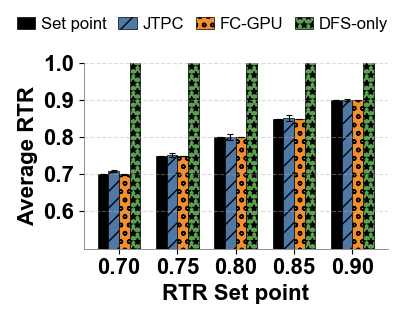

Saved plot to: figures\jetson_rtr_barplot.pdf
Saved plot to: figures\jetson_rtr_barplot.png


In [3]:
# LQR vs FC vs DFS RTR Revision
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---------- FONT / STYLE ----------
plt.rcParams.update({
    "font.family": "Arial",
    "font.weight": "normal",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "axes.labelsize": 16,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ---------------- CONFIG ----------------
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 12

l_root = Path("02_regular_tests/logs/Full_LQR/hist_stereo_mm/")
f_root = Path("02_regular_tests/logs/Full_FC/hist_stereo_mm/")
d_root = Path("02_regular_tests/logs/Full_DFS/hist_stereo_mm/")

setpoints = [0.70, 0.75, 0.80, 0.85, 0.90]
power = [11000, 11500, 12000, 12500, 13000]

save_path = Path("figures")

colors = ["black", "#4E79A7", "#F28E2B", "#59A14F"]
hatches = ["", "//", "oo", "**"]
names = ["Set point", "JTPC", "FC-GPU", "DFS-only"]

# ---------------- HELPERS ----------------
def read_data(filepath: Path):
    if not filepath.exists():
        print(f"Missing: {filepath}")
        return np.array([])
    try:
        return np.loadtxt(filepath)
    except Exception as e:
        print(f"Error reading {filepath}: {e}")
        return np.array([])


def safe_slice(arr):
    if arr.size == 0:
        return arr
    return arr[100:-1] if arr.size > 101 else arr


def find_setpoint_dir(root: Path, sp1: float, sp2: int):
    candidates = [
        root / f"setpoint_{sp1:.2f}",
        root / f"setpoint_{sp2}_{sp1:.2f}_{sp1:.2f}_{sp1:.2f}",
        root / f"setpoint_{sp2}_0.90_0.90_0.90",
    ]

    for c in candidates:
        if c.exists():
            return c

    print(f"No directory found for {root} setpoint {sp1:.2f}, power {sp2}")
    return None


def fc_or_prop_avg_rtr(root: Path, prefix: str, sp1: float):
    means = []
    stds = []

    for p_sp in power:
        run_dir = find_setpoint_dir(root, sp1, p_sp)

        if run_dir is None:
            means.append(np.nan)
            stds.append(np.nan)
            continue

        t1 = read_data(run_dir / f"{prefix}_t1_rtr.txt")
        t2 = read_data(run_dir / f"{prefix}_t2_rtr.txt")
        t3 = read_data(run_dir / f"{prefix}_t3_rtr.txt")

        t1 = safe_slice(t1)
        t2 = safe_slice(t2)
        t3 = safe_slice(t3)

        n = min(len(t1), len(t2), len(t3))

        if n == 0:
            means.append(np.nan)
            stds.append(np.nan)
            continue

        avg_trace = (t1[:n] + t2[:n] + t3[:n]) / 3.0

        means.append(float(np.mean(avg_trace)))
        stds.append(float(np.std(avg_trace)))

    return np.array(means), np.array(stds)


def avg_across_power(root: Path, prefix: str, sp1: float):
    means, stds = fc_or_prop_avg_rtr(root, prefix, sp1)

    valid = ~np.isnan(means)
    if not np.any(valid):
        return np.nan, np.nan

    avg_mean = float(np.mean(means[valid]))
    avg_std = float(np.mean(stds[valid])) if np.any(~np.isnan(stds[valid])) else np.nan

    return avg_mean, avg_std


# ---------------- COLLECT ----------------
setpoint_group_means = []
setpoint_group_stds = []

lqr_group_means = []
lqr_group_stds = []

fc_group_means = []
fc_group_stds = []

dfs_group_means = []
dfs_group_stds = []

for sp1 in setpoints:
    print("RTR setpoint:", sp1)

    l_mean, l_std = avg_across_power(l_root, "LQR", sp1)
    f_mean, f_std = avg_across_power(f_root, "FC_GPU", sp1)
    d_mean, d_std = avg_across_power(d_root, "DFS", sp1)

    setpoint_group_means.append(sp1)
    setpoint_group_stds.append(0.0)

    lqr_group_means.append(l_mean)
    lqr_group_stds.append(l_std)

    fc_group_means.append(f_mean)
    fc_group_stds.append(f_std)

    dfs_group_means.append(d_mean)
    dfs_group_stds.append(d_std)

    print("  LQR avg across power:", l_mean)
    print("  FC-GPU avg across power:", f_mean)
    print("  DFS avg across power:", d_mean)

setpoint_group_means = np.array(setpoint_group_means)
setpoint_group_stds = np.array(setpoint_group_stds)

lqr_group_means = np.array(lqr_group_means)
lqr_group_stds = np.array(lqr_group_stds)

fc_group_means = np.array(fc_group_means)
fc_group_stds = np.array(fc_group_stds)

dfs_group_means = np.array(dfs_group_means)
dfs_group_stds = np.array(dfs_group_stds)

# ---------------- PLOT ----------------
fig, ax = plt.subplots(figsize=(4, 3))

# Reduce group spacing to match the power bar plot.
x = np.arange(len(setpoints)) * 0.82

# Use slightly wider bars, matching the power bar plot.
bar_width = 0.15

all_means = [
    setpoint_group_means,
    lqr_group_means,
    fc_group_means,
    dfs_group_means,
]

all_stds = [
    setpoint_group_stds,
    lqr_group_stds,
    fc_group_stds,
    dfs_group_stds,
]

for i in range(4):
    ax.bar(
        x + (i - 1.5) * bar_width,
        all_means[i],
        bar_width,
        yerr=all_stds[i],
        color=colors[i],
        hatch=hatches[i],
        edgecolor="black",
        linewidth=0.5,
        label=names[i],
        error_kw=dict(
            elinewidth=0.8,
            capsize=2,
            capthick=0.8,
        ),
    )

ax.set_xlabel("RTR Set point", fontsize=LABEL_FONTSIZE, fontweight="bold")
ax.set_ylabel("Average RTR", fontsize=LABEL_FONTSIZE, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels([f"{sp:.2f}" for sp in setpoints], fontweight="bold")

ax.grid(axis="y", linestyle="--", alpha=0.45)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("gray")
ax.spines["left"].set_linewidth(0.6)

ax.spines["bottom"].set_color("gray")
ax.spines["bottom"].set_linewidth(0.6)

handles, labels = ax.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.03),
    ncol=4,
    frameon=False,
    prop={"size": LEGEND_FONTSIZE},
    columnspacing=0.7,
    handlelength=1.1,
    handletextpad=0.35,
    borderaxespad=0.0,
)

ax.set_ylim([0.5, 1.0])
ax.set_yticks([0.6, 0.7, 0.8, 0.9, 1.0])

plt.xticks(fontsize=TICK_FONTSIZE, fontweight="bold")
plt.yticks(fontsize=TICK_FONTSIZE, fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.93])

save_path.mkdir(exist_ok=True)

out_pdf = save_path / "jetson_rtr_barplot.pdf"
out_png = save_path / "jetson_rtr_barplot.png"

plt.savefig(
    out_pdf,
    dpi=300,
    bbox_inches="tight",
    format="pdf",
)

plt.savefig(
    out_png,
    dpi=300,
    bbox_inches="tight",
    format="png",
)

plt.show()

print("Saved plot to:", out_pdf)
print("Saved plot to:", out_png)

Power setpoint: 11000
  LQR avg across RTR setpoints: 0.8741164331874451
  FC-GPU avg across RTR setpoints: 1.0880417396950945
  DFS avg across RTR setpoints: 1.0
Power setpoint: 11500
  LQR avg across RTR setpoints: 0.9389124355929322
  FC-GPU avg across RTR setpoints: 1.0882709725598776
  DFS avg across RTR setpoints: 1.0
Power setpoint: 12000
  LQR avg across RTR setpoints: 0.9913345312130157
  FC-GPU avg across RTR setpoints: 1.088347328227861
  DFS avg across RTR setpoints: 0.9833333333333332
Power setpoint: 12500
  LQR avg across RTR setpoints: 1.0418127629655236
  FC-GPU avg across RTR setpoints: 1.0884605045958629
  DFS avg across RTR setpoints: 1.0
Power setpoint: 13000
Missing: 02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_13000_0.75_0.75_0.75\FC_GPU_t1_period.txt
Missing: 02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_13000_0.75_0.75_0.75\FC_GPU_t2_period.txt
Missing: 02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_13000_0.75_0.75_0.75\FC_GPU_t3_period.t

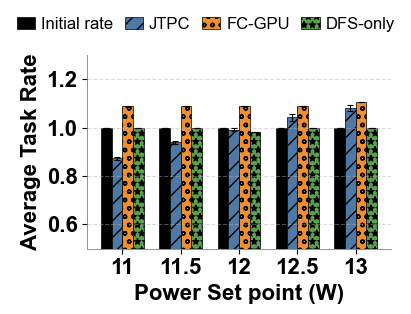

Saved plot to: figures\jetson_task_rate_barplot.pdf
Saved plot to: figures\jetson_task_rate_barplot.png


In [7]:
# LQR vs FC vs DFS Task Rate Revision
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---------- FONT / STYLE ----------
plt.rcParams.update({
    "font.family": "Arial",
    "font.weight": "normal",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "axes.labelsize": 16,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ---------------- CONFIG ----------------
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 12

l_root = Path("02_regular_tests/logs/Full_LQR/hist_stereo_mm/")
f_root = Path("02_regular_tests/logs/Full_FC/hist_stereo_mm/")
d_root = Path("02_regular_tests/logs/Full_DFS/hist_stereo_mm/")

setpoints = [0.70, 0.75, 0.80, 0.85, 0.90]
power = [11000, 11500, 12000, 12500, 13000]

save_path = Path("figures")

colors = ["black", "#4E79A7", "#F28E2B", "#59A14F"]
hatches = ["", "//", "oo", "**"]
names = ["Initial rate", "JTPC", "FC-GPU", "DFS-only"]

# Initial task periods in ms: default_rates=(0.160 0.080 0.0600)
initial_periods = [160.0, 80.0, 60.0]

# ---------------- HELPERS ----------------
def read_data(filepath: Path):
    if not filepath.exists():
        print(f"Missing: {filepath}")
        return np.array([])
    try:
        return np.loadtxt(filepath)
    except Exception as e:
        print(f"Error reading {filepath}: {e}")
        return np.array([])


def safe_slice(arr):
    if arr.size == 0:
        return arr
    return arr[100:-1] if arr.size > 101 else arr


def find_setpoint_dir(root: Path, sp1: float, sp2: int):
    candidates = [
        root / f"setpoint_{sp1:.2f}",
        root / f"setpoint_{sp2}_{sp1:.2f}_{sp1:.2f}_{sp1:.2f}",
        root / f"setpoint_{sp2}_0.90_0.90_0.90",
    ]

    for c in candidates:
        if c.exists():
            return c

    print(f"No directory found for {root} setpoint {sp1:.2f}, power {sp2}")
    return None


def fc_or_prop_avg_task_rate(root: Path, prefix: str, sp2: int):
    means = []
    stds = []

    for sp1 in setpoints:
        run_dir = find_setpoint_dir(root, sp1, sp2)

        if run_dir is None:
            means.append(np.nan)
            stds.append(np.nan)
            continue

        t1 = read_data(run_dir / f"{prefix}_t1_period.txt")
        t2 = read_data(run_dir / f"{prefix}_t2_period.txt")
        t3 = read_data(run_dir / f"{prefix}_t3_period.txt")

        t1 = safe_slice(t1)
        t2 = safe_slice(t2)
        t3 = safe_slice(t3)

        n = min(len(t1), len(t2), len(t3))

        if n == 0:
            means.append(np.nan)
            stds.append(np.nan)
            continue

        t1 = t1[:n]
        t2 = t2[:n]
        t3 = t3[:n]

        valid = (t1 > 0) & (t2 > 0) & (t3 > 0)

        if not np.any(valid):
            means.append(np.nan)
            stds.append(np.nan)
            continue

        task_rate_trace = (
            initial_periods[0] / t1[valid] +
            initial_periods[1] / t2[valid] +
            initial_periods[2] / t3[valid]
        ) / 3.0

        means.append(float(np.mean(task_rate_trace)))
        stds.append(float(np.std(task_rate_trace)))

    return np.array(means), np.array(stds)


def avg_across_setpoints(root: Path, prefix: str, sp2: int):
    means, stds = fc_or_prop_avg_task_rate(root, prefix, sp2)

    valid = ~np.isnan(means)
    if not np.any(valid):
        return np.nan, np.nan

    avg_mean = float(np.mean(means[valid]))
    avg_std = float(np.mean(stds[valid])) if np.any(~np.isnan(stds[valid])) else np.nan

    return avg_mean, avg_std


# ---------------- COLLECT ----------------
setpoint_group_means = []
setpoint_group_stds = []

lqr_group_means = []
lqr_group_stds = []

fc_group_means = []
fc_group_stds = []

dfs_group_means = []
dfs_group_stds = []

for sp2 in power:
    print("Power setpoint:", sp2)

    l_mean, l_std = avg_across_setpoints(l_root, "LQR", sp2)
    f_mean, f_std = avg_across_setpoints(f_root, "FC_GPU", sp2)
    d_mean, d_std = avg_across_setpoints(d_root, "DFS", sp2)

    setpoint_group_means.append(1.0)
    setpoint_group_stds.append(0.0)

    lqr_group_means.append(l_mean)
    lqr_group_stds.append(l_std)

    fc_group_means.append(f_mean)
    fc_group_stds.append(f_std)

    dfs_group_means.append(d_mean)
    dfs_group_stds.append(d_std)

    print("  LQR avg across RTR setpoints:", l_mean)
    print("  FC-GPU avg across RTR setpoints:", f_mean)
    print("  DFS avg across RTR setpoints:", d_mean)

setpoint_group_means = np.array(setpoint_group_means)
setpoint_group_stds = np.array(setpoint_group_stds)

lqr_group_means = np.array(lqr_group_means)
lqr_group_stds = np.array(lqr_group_stds)

fc_group_means = np.array(fc_group_means)
fc_group_stds = np.array(fc_group_stds)

dfs_group_means = np.array(dfs_group_means)
dfs_group_stds = np.array(dfs_group_stds)

# ---------------- PLOT ----------------
fig, ax = plt.subplots(figsize=(4, 3))

# Reduce group spacing to match the power bar plot.
x = np.arange(len(power)) * 0.82

# Use slightly wider bars, matching the power bar plot.
bar_width = 0.15

all_means = [
    setpoint_group_means,
    lqr_group_means,
    fc_group_means,
    dfs_group_means,
]

all_stds = [
    setpoint_group_stds,
    lqr_group_stds,
    fc_group_stds,
    dfs_group_stds,
]

for i in range(4):
    ax.bar(
        x + (i - 1.5) * bar_width,
        all_means[i],
        bar_width,
        yerr=all_stds[i],
        color=colors[i],
        hatch=hatches[i],
        edgecolor="black",
        linewidth=0.5,
        label=names[i],
        error_kw=dict(
            elinewidth=0.8,
            capsize=2,
            capthick=0.8,
        ),
    )

ax.set_xlabel("Power Set point (W)", fontsize=LABEL_FONTSIZE, fontweight="bold")
ax.set_ylabel("Average Task Rate", fontsize=LABEL_FONTSIZE, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels([f"{p / 1000:g}" for p in power], fontweight="bold")

ax.grid(axis="y", linestyle="--", alpha=0.45)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("gray")
ax.spines["left"].set_linewidth(0.6)

ax.spines["bottom"].set_color("gray")
ax.spines["bottom"].set_linewidth(0.6)

handles, labels = ax.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.03),
    ncol=4,
    frameon=False,
    prop={"size": LEGEND_FONTSIZE},
    columnspacing=0.7,
    handlelength=1.1,
    handletextpad=0.35,
    borderaxespad=0.0,
)

ax.set_ylim([0.5, 1.3])
ax.set_yticks([0.6, 0.8, 1.0, 1.2])

plt.xticks(fontsize=TICK_FONTSIZE, fontweight="bold")
plt.yticks(fontsize=TICK_FONTSIZE, fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.93])

save_path.mkdir(exist_ok=True)

out_pdf = save_path / "jetson_task_rate_barplot.pdf"
out_png = save_path / "jetson_task_rate_barplot.png"

plt.savefig(
    out_pdf,
    dpi=300,
    bbox_inches="tight",
    format="pdf",
)

plt.savefig(
    out_png,
    dpi=300,
    bbox_inches="tight",
    format="png",
)

plt.show()

print("Saved plot to:", out_pdf)
print("Saved plot to:", out_png)

Power: 11000
  JTPC effective utility: 0.8648465887217313
  FC-GPU effective utility: 0.9928724176233749
  DFS effective utility: 0.3857602796771715
Power: 11500
  JTPC effective utility: 0.9354270096521631
  FC-GPU effective utility: 1.0515490426420295
  DFS effective utility: 0.40990781352333083
Power: 12000
  JTPC effective utility: 0.9895517059759769
  FC-GPU effective utility: 1.0704818509093716
  DFS effective utility: 0.8470651551061387
Power: 12500
  JTPC effective utility: 1.0394324572011897
  FC-GPU effective utility: 1.0275212621664118
  DFS effective utility: 0.8580042642669046
Power: 13000
Missing: C:\Users\tiare\Desktop\plot\02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_13000_0.75_0.75_0.75\FC_GPU_finalpowervalues.txt
  JTPC effective utility: 1.0772447467242874
  FC-GPU effective utility: 1.0064135073225382
  DFS effective utility: 0.8453892703649031


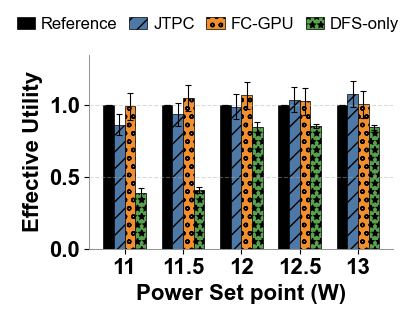

Saved plot to: C:\Users\tiare\Desktop\plot\figures\jetson_effective_utility_barplot.pdf
Saved plot to: C:\Users\tiare\Desktop\plot\figures\jetson_effective_utility_barplot.png

Debug summary:
power_w,method,effective_utility,rate,rtr_factor,deadline_factor,power_factor,power_mean_w
11,JTPC,0.8648,0.8740,0.9893,1.0000,0.9994,11.0058
11,FC-GPU,0.9929,1.0879,0.9903,0.9998,0.9214,11.8644
11,DFS-only,0.3858,1.0000,0.5789,0.6667,0.9996,11.0047
11.5,JTPC,0.9354,0.9388,0.9968,1.0000,0.9992,11.4970
11.5,FC-GPU,1.0515,1.0883,0.9950,1.0000,0.9713,11.8300
11.5,DFS-only,0.4099,1.0000,0.6153,0.6667,0.9993,11.5069
12,JTPC,0.9896,0.9912,0.9991,1.0000,0.9992,11.9993
12,FC-GPU,1.0705,1.0883,0.9950,1.0000,0.9886,11.8628
12,DFS-only,0.8471,0.9833,0.8635,0.9982,0.9995,11.9983
12.5,JTPC,1.0394,1.0415,0.9984,1.0000,0.9996,12.4966
12.5,FC-GPU,1.0275,1.0885,0.9950,1.0000,0.9486,11.8575
12.5,DFS-only,0.8580,1.0000,0.8584,1.0000,0.9996,12.5052
13,JTPC,1.0772,1.0818,0.9976,1.0000,0.9982,12.9773
13,FC-GPU,1.0064,1

In [7]:
# LQR vs FC vs DFS Effective Utility Revision
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---------- FONT / STYLE ----------
plt.rcParams.update({
    "font.family": "Arial",
    "font.weight": "normal",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "axes.labelsize": 16,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ---------------- CONFIG ----------------
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 12

BASE = Path(r"C:\Users\tiare\Desktop\plot")

l_root = BASE / "02_regular_tests/logs/Full_LQR/hist_stereo_mm"
f_root = BASE / "02_regular_tests/logs/Full_FC/hist_stereo_mm"
d_root = BASE / "02_regular_tests/logs/Full_DFS/hist_stereo_mm"

rtr_setpoints = [0.70, 0.75, 0.80, 0.85, 0.90]
power_setpoints = [11000, 11500, 12000, 12500, 13000]  # mW

save_path = BASE / "figures"

colors = ["black", "#4E79A7", "#F28E2B", "#59A14F"]
hatches = ["", "//", "oo", "**"]
names = ["Reference", "JTPC", "FC-GPU", "DFS-only"]

# default_rates=(0.160 0.080 0.0600), converted to ms
initial_period_ms = {
    1: 160.0,
    2: 80.0,
    3: 60.0,
}

# ---------------- HELPERS ----------------
def read_data(filepath: Path):
    if not filepath.exists():
        print(f"Missing: {filepath}")
        return np.array([])
    try:
        return np.loadtxt(filepath)
    except Exception as e:
        print(f"Error reading {filepath}: {e}")
        return np.array([])


def safe_slice(arr):
    if arr.size == 0:
        return arr
    return arr[100:-1] if arr.size > 101 else arr


def find_setpoint_dir(root: Path, rtr_sp: float, power_sp: int):
    candidates = [
        root / f"setpoint_{rtr_sp:.2f}",
        root / f"setpoint_{power_sp}_{rtr_sp:.2f}_{rtr_sp:.2f}_{rtr_sp:.2f}",
        root / f"setpoint_{power_sp}_0.90_0.90_0.90",
    ]

    for c in candidates:
        if c.exists():
            return c

    print(f"No directory found for {root}, RTR={rtr_sp:.2f}, Power={power_sp}")
    return None


def clipped(x, lo=0.0, hi=1.0):
    return max(lo, min(hi, x))


def case_effective_utility(root: Path, prefix: str, rtr_sp: float, power_sp: int):
    run_dir = find_setpoint_dir(root, rtr_sp, power_sp)
    if run_dir is None:
        return np.nan, {}

    # ---------- Power tracking factor ----------
    power_file = run_dir / f"{prefix}_finalpowervalues.txt"
    power = read_data(power_file)
    power = safe_slice(power)

    if power.size == 0:
        return np.nan, {}

    mean_power = float(np.mean(power))

    # Penalize both exceeding and under-utilizing the power setpoint.
    # 1.0 means perfect tracking. Smaller means farther from the setpoint.
    power_tracking_factor = clipped(1.0 - abs(mean_power - power_sp) / power_sp, 0.0, 1.0)

    # ---------- Task-level factors ----------
    rate_utils = []
    rtr_factors = []
    deadline_factors = []

    for i in [1, 2, 3]:
        period_file = run_dir / f"{prefix}_t{i}_period.txt"
        rtr_file = run_dir / f"{prefix}_t{i}_rtr.txt"
        deadline_file = run_dir / f"{prefix}_t{i}_deadline.txt"

        period = safe_slice(read_data(period_file))
        rtr = safe_slice(read_data(rtr_file))
        deadline = safe_slice(read_data(deadline_file))

        period = period[period > 0] if period.size else period

        if period.size == 0 or rtr.size == 0 or deadline.size == 0:
            return np.nan, {}

        mean_period = float(np.mean(period))
        mean_rtr = float(np.mean(rtr))
        mean_deadline = float(np.mean(deadline))

        # 1) normalized task rate: smaller period = higher rate
        rate_util = initial_period_ms[i] / mean_period

        # 2) RTR tracking: 1 means exact setpoint, 0 means very bad tracking
        rtr_factor = clipped(1.0 - abs(mean_rtr - rtr_sp) / rtr_sp, 0.0, 1.0)

        # 3) deadline success: deadline file is percentage
        deadline_factor = clipped(1.0 - mean_deadline / 100.0, 0.0, 1.0)

        rate_utils.append(rate_util)
        rtr_factors.append(rtr_factor)
        deadline_factors.append(deadline_factor)

    normalized_rate_utility = float(np.mean(rate_utils))
    rtr_tracking_factor = float(np.mean(rtr_factors))
    deadline_success_factor = float(np.mean(deadline_factors))

    effective_utility = (
        normalized_rate_utility
        * rtr_tracking_factor
        * deadline_success_factor
        * power_tracking_factor
    )

    debug = {
        "rate": normalized_rate_utility,
        "rtr_factor": rtr_tracking_factor,
        "deadline_factor": deadline_success_factor,
        "power_factor": power_tracking_factor,
        "power_mean_mw": mean_power,
    }

    return float(effective_utility), debug


def method_effective_utility_across_rtr(root: Path, prefix: str, power_sp: int):
    vals = []
    debug_vals = []

    for rtr_sp in rtr_setpoints:
        u, dbg = case_effective_utility(root, prefix, rtr_sp, power_sp)
        if not np.isnan(u):
            vals.append(u)
            debug_vals.append(dbg)

    if len(vals) == 0:
        return np.nan, np.nan, {}

    avg_debug = {}
    for k in ["rate", "rtr_factor", "deadline_factor", "power_factor", "power_mean_mw"]:
        valid = [d[k] for d in debug_vals if k in d]
        avg_debug[k] = float(np.mean(valid)) if valid else np.nan

    return float(np.mean(vals)), float(np.std(vals)), avg_debug


# ---------------- COLLECT ----------------
lqr_group_means = []
lqr_group_stds = []

fc_group_means = []
fc_group_stds = []

dfs_group_means = []
dfs_group_stds = []

ref_group_means = []
ref_group_stds = []

debug_table = []

for p_sp in power_setpoints:
    print("Power:", p_sp)

    l_mean, l_std, l_dbg = method_effective_utility_across_rtr(l_root, "LQR", p_sp)
    f_mean, f_std, f_dbg = method_effective_utility_across_rtr(f_root, "FC_GPU", p_sp)
    d_mean, d_std, d_dbg = method_effective_utility_across_rtr(d_root, "DFS", p_sp)

    lqr_group_means.append(l_mean)
    lqr_group_stds.append(l_std)

    fc_group_means.append(f_mean)
    fc_group_stds.append(f_std)

    dfs_group_means.append(d_mean)
    dfs_group_stds.append(d_std)

    # Reference utility = 1
    ref_group_means.append(1.0)
    ref_group_stds.append(0.0)

    debug_table.append((p_sp, "JTPC", l_mean, l_dbg))
    debug_table.append((p_sp, "FC-GPU", f_mean, f_dbg))
    debug_table.append((p_sp, "DFS-only", d_mean, d_dbg))

    print("  JTPC effective utility:", l_mean)
    print("  FC-GPU effective utility:", f_mean)
    print("  DFS effective utility:", d_mean)

lqr_group_means = np.array(lqr_group_means)
lqr_group_stds = np.array(lqr_group_stds)

fc_group_means = np.array(fc_group_means)
fc_group_stds = np.array(fc_group_stds)

dfs_group_means = np.array(dfs_group_means)
dfs_group_stds = np.array(dfs_group_stds)

ref_group_means = np.array(ref_group_means)
ref_group_stds = np.array(ref_group_stds)

power_w = [p / 1000.0 for p in power_setpoints]

# ---------------- PLOT ----------------
fig, ax = plt.subplots(figsize=(4, 3))

x = np.arange(len(power_w)) * 0.82
bar_width = 0.15

all_means = [
    ref_group_means,
    lqr_group_means,
    fc_group_means,
    dfs_group_means,
]

all_stds = [
    ref_group_stds,
    lqr_group_stds,
    fc_group_stds,
    dfs_group_stds,
]

for i in range(4):
    ax.bar(
        x + (i - 1.5) * bar_width,
        all_means[i],
        bar_width,
        yerr=all_stds[i],
        color=colors[i],
        hatch=hatches[i],
        edgecolor="black",
        linewidth=0.5,
        label=names[i],
        error_kw=dict(
            elinewidth=0.8,
            capsize=2,
            capthick=0.8,
        ),
    )

ax.set_xlabel("Power Set point (W)", fontsize=LABEL_FONTSIZE, fontweight="bold")
ax.set_ylabel("Effective Utility", fontsize=LABEL_FONTSIZE, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels([f"{p:g}" for p in power_w], fontweight="bold")

ax.grid(axis="y", linestyle="--", alpha=0.45)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("gray")
ax.spines["left"].set_linewidth(0.6)

ax.spines["bottom"].set_color("gray")
ax.spines["bottom"].set_linewidth(0.6)

handles, labels = ax.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.03),
    ncol=4,
    frameon=False,
    prop={"size": LEGEND_FONTSIZE},
    columnspacing=0.7,
    handlelength=1.1,
    handletextpad=0.35,
    borderaxespad=0.0,
)

ax.set_ylim([0.0, 1.35])
ax.set_yticks([0.0, 0.5, 1.0])

plt.xticks(fontsize=TICK_FONTSIZE, fontweight="bold")
plt.yticks(fontsize=TICK_FONTSIZE, fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.93])

save_path.mkdir(exist_ok=True)

out_pdf = save_path / "jetson_effective_utility_barplot.pdf"
out_png = save_path / "jetson_effective_utility_barplot.png"

plt.savefig(
    out_pdf,
    dpi=300,
    bbox_inches="tight",
    format="pdf",
)

plt.savefig(
    out_png,
    dpi=300,
    bbox_inches="tight",
    format="png",
)

plt.show()

print("Saved plot to:", out_pdf)
print("Saved plot to:", out_png)

print("\nDebug summary:")
print("power_w,method,effective_utility,rate,rtr_factor,deadline_factor,power_factor,power_mean_w")
for p_sp, method, u, dbg in debug_table:
    print(
        f"{p_sp/1000.0:g},"
        f"{method},"
        f"{u:.4f},"
        f"{dbg.get('rate', np.nan):.4f},"
        f"{dbg.get('rtr_factor', np.nan):.4f},"
        f"{dbg.get('deadline_factor', np.nan):.4f},"
        f"{dbg.get('power_factor', np.nan):.4f},"
        f"{dbg.get('power_mean_mw', np.nan)/1000.0:.4f}"
    )

In [11]:
# LQR vs FC vs DFS Deadline Miss Ratio Table
import numpy as np
from pathlib import Path

# ---------------- CONFIG ----------------
l_root = Path("02_regular_tests/logs/Full_LQR/hist_stereo_mm/")
f_root = Path("02_regular_tests/logs/Full_FC/hist_stereo_mm/")
d_root = Path("02_regular_tests/logs/Full_DFS/hist_stereo_mm/")

setpoints = [0.70, 0.75, 0.80, 0.85, 0.90]
power = [11000, 11500, 12000, 12500, 13000]

save_dir = Path("tables")
save_dir.mkdir(parents=True, exist_ok=True)

out_path = save_dir / "jetson_deadline_miss_table.tex"

methods = [
    ("LQR", l_root, "LQR"),
    ("FC-GPU", f_root, "FC_GPU"),
    ("DFS Only", d_root, "DFS"),
]

# ---------------- HELPERS ----------------
def read_data(filepath: Path):
    if not filepath.exists():
        print(f"Missing: {filepath}")
        return np.array([])

    try:
        return np.loadtxt(filepath)
    except Exception as e:
        print(f"Error reading {filepath}: {e}")
        return np.array([])


def safe_slice(arr):
    if arr.size == 0:
        return arr
    return arr[100:-1] if arr.size > 101 else arr


def find_setpoint_dir(root: Path, rtr_sp: float, p_sp: int):
    candidates = [
        root / f"setpoint_{rtr_sp:.2f}",
        root / f"setpoint_{p_sp}_{rtr_sp:.2f}_{rtr_sp:.2f}_{rtr_sp:.2f}",
        root / f"setpoint_{p_sp}_{rtr_sp}_{rtr_sp}_{rtr_sp}",
    ]

    for c in candidates:
        if c.exists():
            return c

    print(f"No directory found for {root} RTR={rtr_sp:.2f}, power={p_sp}")
    return None


def dmr_for_one_run(run_dir: Path, prefix: str):
    d1 = safe_slice(read_data(run_dir / f"{prefix}_t1_deadline.txt"))
    d2 = safe_slice(read_data(run_dir / f"{prefix}_t2_deadline.txt"))
    d3 = safe_slice(read_data(run_dir / f"{prefix}_t3_deadline.txt"))

    n = min(len(d1), len(d2), len(d3))

    if n == 0:
        return np.nan

    dmr_trace = (d1[:n] + d2[:n] + d3[:n]) / 3.0
    return float(np.mean(dmr_trace))


def avg_dmr_for_rtr_setpoint(root: Path, prefix: str, rtr_sp: float):
    run_means = []

    for p_sp in power:
        run_dir = find_setpoint_dir(root, rtr_sp, p_sp)

        if run_dir is None:
            run_means.append(np.nan)
            continue

        run_means.append(dmr_for_one_run(run_dir, prefix))

    run_means = np.asarray(run_means, dtype=float)
    valid = ~np.isnan(run_means)

    if not np.any(valid):
        return np.nan

    return float(np.mean(run_means[valid]))


def fmt(x):
    if np.isnan(x):
        return "--"
    return f"{x:.2f}"


# ---------------- COLLECT TABLE ----------------
table = {}

for method_name, root, prefix in methods:
    row = []

    for rtr_sp in setpoints:
        val = avg_dmr_for_rtr_setpoint(root, prefix, rtr_sp)
        row.append(val)

    table[method_name] = row

# ---------------- LATEX TABLE ----------------
header_cols = " & ".join([f"\\textbf{{{sp:.2f}}}" for sp in setpoints])

lines = []
lines.append(r"\begin{table}[ht]")
lines.append(r"\centering")
lines.append(r"\scriptsize")
lines.append(r"\renewcommand{\arraystretch}{1.1}")
lines.append(r"\caption{Deadline miss ratio (\%) for different RTR setpoints on the Jetson platform.}")
lines.append(r"\begin{tabular}{l|" + "c" * len(setpoints) + r"}")
lines.append(r"\hline\hline")
lines.append(r"\textbf{Solution} & " + header_cols + r" \\")
lines.append(r"\hline")

# Optional setpoint baseline row
lines.append("Setpoint & " + " & ".join(["0.00"] * len(setpoints)) + r" \\")

for method_name, vals in table.items():
    lines.append(method_name + " & " + " & ".join(fmt(v) for v in vals) + r" \\")

lines.append(r"\hline\hline")
lines.append(r"\end{tabular}")
lines.append(r"\label{tab:jetson_deadline_miss}")
lines.append(r"\end{table}")

latex = "\n".join(lines)

print(latex)

out_path.write_text(latex)
print(f"\nSaved LaTeX table to: {out_path}")

\begin{table}[ht]
\centering
\scriptsize
\renewcommand{\arraystretch}{1.1}
\caption{Deadline miss ratio (\%) for different RTR setpoints on the Jetson platform.}
\begin{tabular}{l|ccccc}
\hline\hline
\textbf{Solution} & \textbf{0.70} & \textbf{0.75} & \textbf{0.80} & \textbf{0.85} & \textbf{0.90} \\
\hline
Setpoint & 0.00 & 0.00 & 0.00 & 0.00 & 0.00 \\
LQR & 0.00 & 0.00 & 0.00 & 0.00 & 0.00 \\
FC-GPU & 0.00 & 0.00 & 0.00 & 0.00 & 0.00 \\
DFS Only & 13.51 & 13.33 & 13.33 & 6.67 & 13.33 \\
\hline\hline
\end{tabular}
\label{tab:jetson_deadline_miss}
\end{table}

Saved LaTeX table to: tables\jetson_deadline_miss_table.tex


In [4]:
# LQR vs FC vs DFS Power Violation Ratio Table
# Columns = power caps: 11W, 11.5W, 12W, 12.5W, 13W
# PVR = percentage of steady-state power samples above the true power cap
# Steady-state window = last 60 control periods, excluding final shutdown point

import numpy as np
from pathlib import Path

# ---------------- CONFIG ----------------
l_root = Path("logs/PVR_margin_LQR/hist_stereo_mm")
f_root = Path("logs/PVR_margin_FC/hist_stereo_mm")
d_root = Path("logs/PVR_margin_DFS/hist_stereo_mm")

rtr_setpoints = [0.70, 0.75, 0.80, 0.85, 0.90]
power_caps = [11000, 11500, 12000, 12500, 13000]
margin = 200

save_dir = Path("tables")
save_dir.mkdir(parents=True, exist_ok=True)

out_path = save_dir / "jetson_pvr_margin_table.tex"

methods = [
    ("LQR", l_root, "LQR"),
    ("FC-GPU", f_root, "FC_GPU"),
    ("DFS Only", d_root, "DFS"),
]

# ---------------- HELPERS ----------------
def read_data(filepath: Path):
    if not filepath.exists():
        print(f"Missing: {filepath}")
        return np.array([])

    try:
        return np.loadtxt(filepath)
    except Exception as e:
        print(f"Error reading {filepath}: {e}")
        return np.array([])


def safe_slice(arr):
    if arr.size == 0:
        return arr

    # Use only the last 60 steady-state control periods.
    # Exclude the final point to avoid shutdown artifact.
    if arr.size > 61:
        return arr[-61:-1]

    return arr


def find_cap_dir(root: Path, cap: int, rtr_sp: float):
    ctrl_power = cap - margin

    candidates = [
        root / f"cap_{cap}_ctrl_{ctrl_power}_{rtr_sp:.2f}_{rtr_sp:.2f}_{rtr_sp:.2f}",
        root / f"cap_{cap}_ctrl_{ctrl_power}_{rtr_sp}_{rtr_sp}_{rtr_sp}",
    ]

    for c in candidates:
        if c.exists():
            return c

    print(f"No directory found for {root}, cap={cap}, ctrl={ctrl_power}, RTR={rtr_sp:.2f}")
    return None


def pvr_for_one_run(run_dir: Path, prefix: str, cap: int):
    p_all = read_data(run_dir / f"{prefix}_finalpowervalues.txt")
    p = safe_slice(p_all)

    if p.size == 0:
        return np.nan

    # PVR = percentage of steady-state samples above true cap.
    pvr_trace = (p > cap).astype(float) * 100.0
    return float(np.mean(pvr_trace))


def avg_pvr_for_power_cap(root: Path, prefix: str, cap: int):
    run_means = []

    for rtr_sp in rtr_setpoints:
        run_dir = find_cap_dir(root, cap, rtr_sp)

        if run_dir is None:
            run_means.append(np.nan)
            continue

        run_means.append(pvr_for_one_run(run_dir, prefix, cap))

    run_means = np.asarray(run_means, dtype=float)
    valid = ~np.isnan(run_means)

    if not np.any(valid):
        return np.nan

    return float(np.mean(run_means[valid]))


def fmt(x):
    if np.isnan(x):
        return "--"
    return f"{x:.2f}"


# ---------------- COLLECT TABLE ----------------
table = {}

for method_name, root, prefix in methods:
    row = []

    for cap in power_caps:
        val = avg_pvr_for_power_cap(root, prefix, cap)
        row.append(val)

    table[method_name] = row


# ---------------- LATEX TABLE ----------------
header_cols = " & ".join([f"\\textbf{{{cap/1000:g}W}}" for cap in power_caps])

lines = []
lines.append(r"\begin{table}[ht]")
lines.append(r"\centering")
lines.append(r"\scriptsize")
lines.append(r"\renewcommand{\arraystretch}{1.1}")
lines.append(r"\caption{Power violation ratio (\%) under runtime safety-margin control on the Jetson platform. The violation is computed against the original power cap, while the controller uses a 200 mW lower internal setpoint.}")
lines.append(r"\begin{tabular}{l|" + "c" * len(power_caps) + r"}")
lines.append(r"\hline\hline")
lines.append(r"\textbf{Solution} & " + header_cols + r" \\")
lines.append(r"\hline")

lines.append("Setpoint & " + " & ".join(["0.00"] * len(power_caps)) + r" \\")

for method_name, vals in table.items():
    lines.append(method_name + " & " + " & ".join(fmt(v) for v in vals) + r" \\")

lines.append(r"\hline\hline")
lines.append(r"\end{tabular}")
lines.append(r"\label{tab:jetson_pvr_margin}")
lines.append(r"\end{table}")

latex = "\n".join(lines)

print(latex)

out_path.write_text(latex)
print(f"\nSaved LaTeX table to: {out_path}")

\begin{table}[ht]
\centering
\scriptsize
\renewcommand{\arraystretch}{1.1}
\caption{Power violation ratio (\%) under runtime safety-margin control on the Jetson platform. The violation is computed against the original power cap, while the controller uses a 200 mW lower internal setpoint.}
\begin{tabular}{l|ccccc}
\hline\hline
\textbf{Solution} & \textbf{11W} & \textbf{11.5W} & \textbf{12W} & \textbf{12.5W} & \textbf{13W} \\
\hline
Setpoint & 0.00 & 0.00 & 0.00 & 0.00 & 0.00 \\
LQR & 0.67 & 1.67 & 1.67 & 3.33 & 13.33 \\
FC-GPU & 34.00 & 9.67 & 2.33 & 1.33 & 0.00 \\
DFS Only & 0.00 & 1.67 & 1.33 & 1.67 & 13.67 \\
\hline\hline
\end{tabular}
\label{tab:jetson_pvr_margin}
\end{table}

Saved LaTeX table to: tables\jetson_pvr_margin_table.tex


In [1]:
import numpy as np
import pandas as pd
from pathlib import Path

roots = {
    "LQR": ("logs/PVR_margin_LQR/hist_stereo_mm", "LQR"),
    "FC-GPU": ("logs/PVR_margin_FC/hist_stereo_mm", "FC_GPU"),
    "DFS": ("logs/PVR_margin_DFS/hist_stereo_mm", "DFS"),
}

rtrs = [0.70, 0.75, 0.80, 0.85, 0.90]
caps = [11000, 11500, 12000, 12500, 13000]
margin = 200

def read_vals(path):
    path = Path(path)
    if not path.exists():
        return np.array([])
    try:
        return np.loadtxt(path)
    except Exception:
        return np.array([])

def slice_100_to_end(x):
    if len(x) > 101:
        return x[100:-1]
    return x

def slice_last60(x):
    if len(x) > 61:
        return x[-61:-1]
    return x

rows = []

for method, (root, prefix) in roots.items():
    root = Path(root)

    for cap in caps:
        ctrl = cap - margin

        for rtr in rtrs:
            d = root / f"cap_{cap}_ctrl_{ctrl}_{rtr:.2f}_{rtr:.2f}_{rtr:.2f}"

            p_all = read_vals(d / f"{prefix}_finalpowervalues.txt")
            ps_all = read_vals(d / f"{prefix}__powersetpoint.txt")

            d1_all = read_vals(d / f"{prefix}_t1_deadline.txt")
            d2_all = read_vals(d / f"{prefix}_t2_deadline.txt")
            d3_all = read_vals(d / f"{prefix}_t3_deadline.txt")

            p_last60 = slice_last60(p_all)
            p_100 = slice_100_to_end(p_all)

            d1 = slice_100_to_end(d1_all)
            d2 = slice_100_to_end(d2_all)
            d3 = slice_100_to_end(d3_all)
            n = min(len(d1), len(d2), len(d3))

            if len(p_all) == 0:
                rows.append({
                    "method": method,
                    "cap": cap,
                    "ctrl": ctrl,
                    "rtr": rtr,
                    "status": "missing power",
                })
                continue

            # Definition A: sample-count PVR
            pvr_count_last60 = np.mean(p_last60 > cap) * 100 if len(p_last60) else np.nan
            pvr_count_100 = np.mean(p_100 > cap) * 100 if len(p_100) else np.nan

            # Definition B: overshoot-magnitude ratio
            pvr_excess_last60 = np.mean(np.maximum(p_last60 - cap, 0.0) / cap * 100) if len(p_last60) else np.nan
            pvr_excess_100 = np.mean(np.maximum(p_100 - cap, 0.0) / cap * 100) if len(p_100) else np.nan

            # PE, old heatmap metric
            pe_last60 = np.mean(np.abs(p_last60 - cap) / cap * 100) if len(p_last60) else np.nan
            pe_100 = np.mean(np.abs(p_100 - cap) / cap * 100) if len(p_100) else np.nan

            dmr = np.nan
            if n > 0:
                dmr = np.mean((d1[:n] + d2[:n] + d3[:n]) / 3.0)

            rows.append({
                "method": method,
                "cap": cap,
                "ctrl": ctrl,
                "rtr": rtr,
                "n_power_all": len(p_all),
                "n_power_last60": len(p_last60),
                "n_power_100": len(p_100),
                "powersetpoint_unique": ",".join(map(lambda x: str(int(x)), np.unique(ps_all))) if len(ps_all) else "NA",
                "power_mean_last60": np.mean(p_last60) if len(p_last60) else np.nan,
                "power_max_last60": np.max(p_last60) if len(p_last60) else np.nan,
                "above_count_last60": int(np.sum(p_last60 > cap)) if len(p_last60) else 0,
                "pvr_count_last60": pvr_count_last60,
                "pvr_count_100": pvr_count_100,
                "pvr_excess_last60": pvr_excess_last60,
                "pvr_excess_100": pvr_excess_100,
                "pe_last60": pe_last60,
                "pe_100": pe_100,
                "dmr_100": dmr,
                "dir": str(d),
            })

df = pd.DataFrame(rows)
df.to_csv("tables/pvr_margin_debug_check.csv", index=False)

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 50)

print("=== Aggregated by method and cap ===")
print(
    df.groupby(["method", "cap"])[
        ["pvr_count_last60", "pvr_excess_last60", "pe_last60", "dmr_100"]
    ].mean().round(3)
)

print("\n=== Suspicious cases: LQR/DFS PVR count > 10% ===")
print(
    df[
        (df["method"].isin(["LQR", "DFS"])) &
        (df["pvr_count_last60"] > 10)
    ][
        ["method", "cap", "ctrl", "rtr", "pvr_count_last60",
         "pvr_excess_last60", "pe_last60", "power_mean_last60",
         "power_max_last60", "above_count_last60", "n_power_last60",
         "powersetpoint_unique", "dir"]
    ].sort_values(["method", "cap", "rtr"])
)

print("\nSaved: tables/pvr_margin_debug_check.csv")

=== Aggregated by method and cap ===
              pvr_count_last60  pvr_excess_last60  pe_last60  dmr_100
method cap                                                           
DFS    11000             0.000              0.000      1.824   33.333
       11500             1.667              0.007      1.750   33.333
       12000             1.333              0.006      1.688   33.333
       12500             1.667              0.006      1.625    0.000
       13000            13.667              0.078      1.692    0.000
FC-GPU 11000            34.000              1.407      5.285    0.000
       11500             9.667              0.316      7.646    0.000
       12000             2.333              0.049     10.283    0.000
       12500             1.333              0.021     13.628    0.000
       13000             0.000              0.000     17.221    0.000
LQR    11000             0.667              0.033      1.884    0.000
       11500             1.667              0.008    

Power: 11000
  JTPC    task utility=1.042
  FC-GPU  task utility=1.188
  DFS     task utility=1.000
Power: 11500
  JTPC    task utility=1.096
  FC-GPU  task utility=1.187
  DFS     task utility=1.000
Power: 12000
  JTPC    task utility=1.143
  FC-GPU  task utility=1.187
  DFS     task utility=1.000
Power: 12500
  JTPC    task utility=1.186
  FC-GPU  task utility=1.187
  DFS     task utility=1.000
Power: 13000
  JTPC    task utility=1.229
  FC-GPU  task utility=1.187
  DFS     task utility=1.000


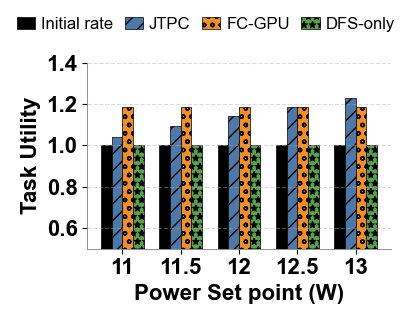

Saved plot to: C:\Users\tiare\Desktop\plot\figures\jetson_task_utility_barplot.pdf
Saved plot to: C:\Users\tiare\Desktop\plot\figures\jetson_task_utility_barplot.png


In [13]:
# JTPC vs FC-GPU vs DFS Task Utility Barplot
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---------- FONT / STYLE ----------
plt.rcParams.update({
    "font.family": "Arial",
    "font.weight": "normal",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "axes.labelsize": 16,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ---------------- CONFIG ----------------
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 12

root = Path(r"C:\Users\tiare\Desktop\plot\main_temp")

f_root = root / "FC" / "hist_stereo_mm"
l_root = root / "JTPC" / "hist_stereo_mm"
d_root = root / "DFS" / "hist_stereo_mm"

power = [11000, 11500, 12000, 12500, 13000]
rtr = 0.90

save_path = root.parent / "figures"

# Initial periods in ms for hist, stereo, mm
initial_periods = {
    1: 160.0,
    2: 80.0,
    3: 60.0,
}

colors = ["black", "#4E79A7", "#F28E2B", "#59A14F"]
hatches = ["", "//", "oo", "**"]
names = ["Initial rate", "JTPC", "FC-GPU", "DFS-only"]

# ---------------- HELPERS ----------------
def read_data(filepath: Path):
    if not filepath.exists():
        print(f"Missing: {filepath}")
        return np.array([])
    try:
        return np.loadtxt(filepath)
    except Exception as e:
        print(f"Error reading {filepath}: {e}")
        return np.array([])


def find_setpoint_dir(root_dir: Path, p_sp: int, rtr_sp: float):
    candidates = [
        root_dir / f"setpoint_{p_sp}_{rtr_sp:.2f}_{rtr_sp:.2f}_{rtr_sp:.2f}",
        root_dir / f"setpoint_{p_sp}_0.90_0.90_0.90",
    ]

    for c in candidates:
        if c.exists():
            return c

    print(f"No directory found for {root_dir}, power={p_sp}, rtr={rtr_sp:.2f}")
    return None


def task_utility_for_case(root_dir: Path, prefix: str, p_sp: int, rtr_sp: float):
    run_dir = find_setpoint_dir(root_dir, p_sp, rtr_sp)

    if run_dir is None:
        return np.nan

    task_means = []

    for task_id, init_period in initial_periods.items():
        period_file = run_dir / f"{prefix}_t{task_id}_period.txt"
        period = read_data(period_file)

        if period.size == 0:
            continue

        period = period[np.isfinite(period)]
        period = period[period > 0]

        if period.size == 0:
            continue

        # Normalized task utility / rate:
        # init_period / current_period
        util = init_period / period
        task_means.append(float(np.mean(util)))

    if len(task_means) == 0:
        return np.nan

    return float(np.mean(task_means))


# ---------------- COLLECT ----------------
lqr_group_means = []
fc_group_means = []
dfs_group_means = []
initial_group_means = []

for p_sp in power:
    print("Power:", p_sp)

    l_mean = task_utility_for_case(l_root, "LQR", p_sp, rtr)
    f_mean = task_utility_for_case(f_root, "FC_GPU", p_sp, rtr)
    d_mean = task_utility_for_case(d_root, "DFS", p_sp, rtr)

    lqr_group_means.append(l_mean)
    fc_group_means.append(f_mean)
    dfs_group_means.append(d_mean)
    initial_group_means.append(1.0)

    print(f"  JTPC    task utility={l_mean:.3f}")
    print(f"  FC-GPU  task utility={f_mean:.3f}")
    print(f"  DFS     task utility={d_mean:.3f}")

lqr_group_means = np.array(lqr_group_means)
fc_group_means = np.array(fc_group_means)
dfs_group_means = np.array(dfs_group_means)
initial_group_means = np.array(initial_group_means)

power_w = [p / 1000.0 for p in power]

# ---------------- PLOT ----------------
fig, ax = plt.subplots(figsize=(4, 3))

x = np.arange(len(power_w)) * 0.82
bar_width = 0.15

all_means = [
    initial_group_means,
    lqr_group_means,
    fc_group_means,
    dfs_group_means,
]

for i in range(4):
    ax.bar(
        x + (i - 1.5) * bar_width,
        all_means[i],
        bar_width,
        color=colors[i],
        hatch=hatches[i],
        edgecolor="black",
        linewidth=0.5,
        label=names[i],
    )

ax.set_xlabel("Power Set point (W)", fontsize=LABEL_FONTSIZE, fontweight="bold")
ax.set_ylabel("Task Utility", fontsize=LABEL_FONTSIZE, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels([f"{p:g}" for p in power_w], fontweight="bold")

ax.grid(axis="y", linestyle="--", alpha=0.45)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("gray")
ax.spines["left"].set_linewidth(0.6)

ax.spines["bottom"].set_color("gray")
ax.spines["bottom"].set_linewidth(0.6)

handles, labels = ax.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.03),
    ncol=4,
    frameon=False,
    prop={"size": LEGEND_FONTSIZE},
    columnspacing=0.7,
    handlelength=1.1,
    handletextpad=0.35,
    borderaxespad=0.0,
)

ax.set_ylim([0.5, 1.4])
ax.set_yticks([0.6,0.8,1.0, 1.2, 1.4])

plt.xticks(fontsize=TICK_FONTSIZE, fontweight="bold")
plt.yticks(fontsize=TICK_FONTSIZE, fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.93])

save_path.mkdir(exist_ok=True)

out_pdf = save_path / "jetson_task_utility_barplot.pdf"
out_png = save_path / "jetson_task_utility_barplot.png"

plt.savefig(
    out_pdf,
    dpi=300,
    bbox_inches="tight",
    format="pdf",
)

plt.savefig(
    out_png,
    dpi=300,
    bbox_inches="tight",
    format="png",
)

plt.show()

print("Saved plot to:", out_pdf)
print("Saved plot to:", out_png)

Power: 11000
  JTPC    temp_mean=57.809 C, delta_mean=5.174 C, power_mean=11.089 W, delta_max=7.521 C
  FC-GPU  temp_mean=58.829 C, delta_mean=7.110 C, power_mean=12.148 W, delta_max=10.032 C
  DFS     temp_mean=57.525 C, delta_mean=5.494 C, power_mean=11.031 W, delta_max=7.625 C
Power: 11500
  JTPC    temp_mean=58.201 C, delta_mean=5.618 C, power_mean=11.508 W, delta_max=7.854 C
  FC-GPU  temp_mean=58.668 C, delta_mean=7.033 C, power_mean=12.197 W, delta_max=9.865 C
  DFS     temp_mean=57.955 C, delta_mean=5.872 C, power_mean=11.481 W, delta_max=8.385 C
Power: 12000
  JTPC    temp_mean=58.490 C, delta_mean=6.386 C, power_mean=11.925 W, delta_max=9.021 C
  FC-GPU  temp_mean=58.956 C, delta_mean=7.206 C, power_mean=12.236 W, delta_max=10.093 C
  DFS     temp_mean=58.603 C, delta_mean=6.354 C, power_mean=11.965 W, delta_max=9.001 C
Power: 12500
  JTPC    temp_mean=58.913 C, delta_mean=6.851 C, power_mean=12.383 W, delta_max=9.531 C
  FC-GPU  temp_mean=58.897 C, delta_mean=7.074 C, power_

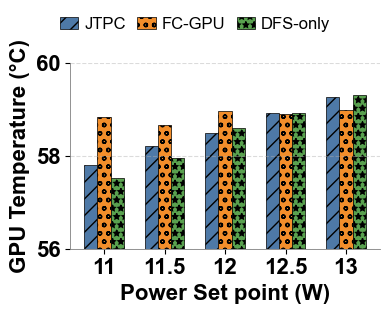

Saved plot to: C:\Users\tiare\Desktop\plot\figures\jetson_gpu_temperature_barplot.pdf
Saved plot to: C:\Users\tiare\Desktop\plot\figures\jetson_gpu_temperature_barplot.png


In [10]:
# JTPC vs FC-GPU vs DFS GPU Temperature Barplot
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
import re

# ---------- FONT / STYLE ----------
plt.rcParams.update({
    "font.family": "Arial",
    "font.weight": "normal",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "axes.labelsize": 16,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ---------------- CONFIG ----------------
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 12

root = Path(r"C:\Users\tiare\Desktop\plot\main_temp")

f_root = root / "FC" / "hist_stereo_mm"
l_root = root / "JTPC" / "hist_stereo_mm"
d_root = root / "DFS" / "hist_stereo_mm"

power = [11000, 11500, 12000, 12500, 13000]
rtr = 0.90

save_path = root.parent / "figures"

colors = ["#4E79A7", "#F28E2B", "#59A14F"]
hatches = ["//", "oo", "**"]
names = ["JTPC", "FC-GPU", "DFS-only"]

# ---------------- HELPERS ----------------
def parse_tegrastats_temp(filepath: Path):
    rows = []

    if not filepath.exists():
        print(f"Missing: {filepath}")
        return rows

    for line in filepath.read_text(errors="ignore").splitlines():
        gpu_m = re.search(r"gpu@([0-9.]+)C", line)
        tj_m = re.search(r"tj@([0-9.]+)C", line)
        vdd_m = re.search(r"VDD_IN\s+([0-9.]+)mW", line)
        gr3d_m = re.search(r"GR3D_FREQ\s+([0-9]+)%", line)

        if not gpu_m or not vdd_m:
            continue

        rows.append({
            "gpu": float(gpu_m.group(1)),
            "tj": float(tj_m.group(1)) if tj_m else np.nan,
            "power_w": float(vdd_m.group(1)) / 1000.0,
            "gr3d": float(gr3d_m.group(1)) if gr3d_m else np.nan,
        })

    return rows


def find_setpoint_dir(root_dir: Path, p_sp: int, rtr_sp: float):
    candidates = [
        root_dir / f"setpoint_{p_sp}_{rtr_sp:.2f}_{rtr_sp:.2f}_{rtr_sp:.2f}",
        root_dir / f"setpoint_{p_sp}_0.90_0.90_0.90",
    ]

    for c in candidates:
        if c.exists():
            return c

    print(f"No directory found for {root_dir}, power={p_sp}, rtr={rtr_sp:.2f}")
    return None


def gpu_temp_for_case(root_dir: Path, p_sp: int, rtr_sp: float):
    run_dir = find_setpoint_dir(root_dir, p_sp, rtr_sp)

    if run_dir is None:
        return np.nan, np.nan, np.nan, np.nan

    temp_log = run_dir / "tegrastats_temp.log"
    rows = parse_tegrastats_temp(temp_log)

    if len(rows) == 0:
        return np.nan, np.nan, np.nan, np.nan

    # Initial baseline temperature: first 3 samples.
    start_gpu = np.mean([r["gpu"] for r in rows[:3]])

    # Active samples: GPU busy or board input power high.
    active = [
        r for r in rows
        if (not np.isnan(r["gr3d"]) and r["gr3d"] >= 10) or r["power_w"] >= 8.0
    ]

    if len(active) == 0:
        return np.nan, start_gpu, np.nan, np.nan

    gpu = np.array([r["gpu"] for r in active], dtype=float)
    power_w = np.array([r["power_w"] for r in active], dtype=float)

    gpu_mean = float(np.mean(gpu))
    active_power_mean = float(np.mean(power_w))
    delta_mean = float(gpu_mean - start_gpu)
    delta_max = float(np.max(gpu - start_gpu))

    return gpu_mean, active_power_mean, delta_mean, delta_max


# ---------------- COLLECT ----------------
lqr_temp_means = []
lqr_power_means = []
lqr_delta_means = []
lqr_delta_max = []

fc_temp_means = []
fc_power_means = []
fc_delta_means = []
fc_delta_max = []

dfs_temp_means = []
dfs_power_means = []
dfs_delta_means = []
dfs_delta_max = []

for p_sp in power:
    print("Power:", p_sp)

    l_temp, l_pwr, l_delta, l_max = gpu_temp_for_case(l_root, p_sp, rtr)
    f_temp, f_pwr, f_delta, f_max = gpu_temp_for_case(f_root, p_sp, rtr)
    d_temp, d_pwr, d_delta, d_max = gpu_temp_for_case(d_root, p_sp, rtr)

    lqr_temp_means.append(l_temp)
    lqr_power_means.append(l_pwr)
    lqr_delta_means.append(l_delta)
    lqr_delta_max.append(l_max)

    fc_temp_means.append(f_temp)
    fc_power_means.append(f_pwr)
    fc_delta_means.append(f_delta)
    fc_delta_max.append(f_max)

    dfs_temp_means.append(d_temp)
    dfs_power_means.append(d_pwr)
    dfs_delta_means.append(d_delta)
    dfs_delta_max.append(d_max)

    print(f"  JTPC    temp_mean={l_temp:.3f} C, delta_mean={l_delta:.3f} C, power_mean={l_pwr:.3f} W, delta_max={l_max:.3f} C")
    print(f"  FC-GPU  temp_mean={f_temp:.3f} C, delta_mean={f_delta:.3f} C, power_mean={f_pwr:.3f} W, delta_max={f_max:.3f} C")
    print(f"  DFS     temp_mean={d_temp:.3f} C, delta_mean={d_delta:.3f} C, power_mean={d_pwr:.3f} W, delta_max={d_max:.3f} C")

lqr_temp_means = np.array(lqr_temp_means)
fc_temp_means = np.array(fc_temp_means)
dfs_temp_means = np.array(dfs_temp_means)

power_w = [p / 1000.0 for p in power]

# ---------------- PLOT ----------------
fig, ax = plt.subplots(figsize=(4, 3))

x = np.arange(len(power_w)) * 0.82
bar_width = 0.18

all_means = [
    lqr_temp_means,
    fc_temp_means,
    dfs_temp_means,
]

for i in range(3):
    ax.bar(
        x + (i - 1) * bar_width,
        all_means[i],
        bar_width,
        color=colors[i],
        hatch=hatches[i],
        edgecolor="black",
        linewidth=0.5,
        label=names[i],
    )

ax.set_xlabel("Power Set point (W)", fontsize=LABEL_FONTSIZE, fontweight="bold")
ax.set_ylabel("GPU Temperature (°C)", fontsize=LABEL_FONTSIZE, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels([f"{p:g}" for p in power_w], fontweight="bold")

ax.grid(axis="y", linestyle="--", alpha=0.45)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("gray")
ax.spines["left"].set_linewidth(0.6)

ax.spines["bottom"].set_color("gray")
ax.spines["bottom"].set_linewidth(0.6)

handles, labels = ax.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.03),
    ncol=3,
    frameon=False,
    prop={"size": LEGEND_FONTSIZE},
    columnspacing=0.7,
    handlelength=1.1,
    handletextpad=0.35,
    borderaxespad=0.0,
)

# Temperature range. Use compressed y-axis to show method differences.
all_vals = np.concatenate([
    lqr_temp_means,
    fc_temp_means,
    dfs_temp_means,
])

ax.set_ylim([56, 60])
ax.set_yticks([56, 58, 60])

plt.xticks(fontsize=TICK_FONTSIZE, fontweight="bold")
plt.yticks(fontsize=TICK_FONTSIZE, fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.93])

save_path.mkdir(exist_ok=True)

out_pdf = save_path / "jetson_gpu_temperature_barplot.pdf"
out_png = save_path / "jetson_gpu_temperature_barplot.png"

plt.savefig(
    out_pdf,
    dpi=300,
    bbox_inches="tight",
    format="pdf",
)

plt.savefig(
    out_png,
    dpi=300,
    bbox_inches="tight",
    format="png",
)

plt.show()

print("Saved plot to:", out_pdf)
print("Saved plot to:", out_png)

RTR setpoint: 0.70, fixed power: 13.0W
  JTPC: 0.7013857857142858
  FC-GPU: 0.6997779523809523
  DFS-only: 0.7598522857142856
RTR setpoint: 0.75, fixed power: 13.0W
Missing: 02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_13000_0.75_0.75_0.75\FC_GPU_t1_rtr.txt
Missing: 02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_13000_0.75_0.75_0.75\FC_GPU_t2_rtr.txt
Missing: 02_regular_tests\logs\Full_FC\hist_stereo_mm\setpoint_13000_0.75_0.75_0.75\FC_GPU_t3_rtr.txt
  JTPC: 0.7511991666666666
  FC-GPU: nan
  DFS-only: 0.7597445238095238
RTR setpoint: 0.80, fixed power: 13.0W
  JTPC: 0.8025422142857142
  FC-GPU: 0.7997049523809523
  DFS-only: 0.7597982142857141
RTR setpoint: 0.85, fixed power: 13.0W
  JTPC: 0.8536303809523808
  FC-GPU: 0.8497445238095238
  DFS-only: 0.7584314761904762
RTR setpoint: 0.90, fixed power: 13.0W
  JTPC: 0.9006992619047621
  FC-GPU: 0.8997188333333332
  DFS-only: 0.7609726904761905


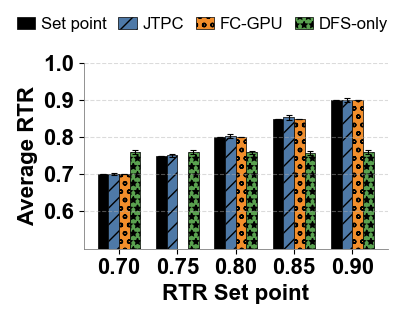

Saved plot to: figures\jetson_rtr_barplot.pdf
Saved plot to: figures\jetson_rtr_barplot.png


In [22]:
# LQR vs FC vs DFS RTR Revision
# Single-degree-of-freedom slice:
# Fixed power setpoint = 12W, sweep RTR setpoint.

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---------- FONT / STYLE ----------
plt.rcParams.update({
    "font.family": "Arial",
    "font.weight": "normal",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "axes.labelsize": 16,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ---------------- CONFIG ----------------
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 12

# Use adaptive FC-GPU log.
l_root = Path("02_regular_tests/logs/Full_LQR/hist_stereo_mm/")
f_root = Path("02_regular_tests/logs/Full_FC/hist_stereo_mm/")
d_root = Path("02_regular_tests/logs/Full_DFS/hist_stereo_mm/")

setpoints = [0.70, 0.75, 0.80, 0.85, 0.90]

# Fixed power point for RTR sweep.
FIXED_POWER = 13000  # 12W

save_path = Path("figures")

colors = ["black", "#4E79A7", "#F28E2B", "#59A14F"]
hatches = ["", "//", "oo", "**"]
names = ["Set point", "JTPC", "FC-GPU", "DFS-only"]

# ---------------- HELPERS ----------------
def read_data(filepath: Path):
    if not filepath.exists():
        print(f"Missing: {filepath}")
        return np.array([])
    try:
        return np.loadtxt(filepath)
    except Exception as e:
        print(f"Error reading {filepath}: {e}")
        return np.array([])


def safe_slice(arr):
    if arr.size == 0:
        return arr
    return arr[100:-1] if arr.size > 101 else arr


def find_setpoint_dir(root: Path, rtr_sp: float, power_sp: int):
    candidates = [
        root / f"setpoint_{power_sp}_{rtr_sp:.2f}_{rtr_sp:.2f}_{rtr_sp:.2f}",
        root / f"setpoint_{power_sp}_0.90_0.90_0.90",
        root / f"setpoint_{rtr_sp:.2f}",
    ]

    for c in candidates:
        if c.exists():
            return c

    print(f"No directory found for {root}, RTR={rtr_sp:.2f}, power={power_sp}")
    return None


def avg_rtr_for_case(root: Path, prefix: str, rtr_sp: float, power_sp: int):
    run_dir = find_setpoint_dir(root, rtr_sp, power_sp)

    if run_dir is None:
        return np.nan, np.nan

    t1 = read_data(run_dir / f"{prefix}_t1_rtr.txt")
    t2 = read_data(run_dir / f"{prefix}_t2_rtr.txt")
    t3 = read_data(run_dir / f"{prefix}_t3_rtr.txt")

    t1 = safe_slice(t1)
    t2 = safe_slice(t2)
    t3 = safe_slice(t3)

    n = min(len(t1), len(t2), len(t3))

    if n == 0:
        return np.nan, np.nan

    avg_trace = (t1[:n] + t2[:n] + t3[:n]) / 3.0

    return float(np.mean(avg_trace)), float(np.std(avg_trace))


# ---------------- COLLECT ----------------
setpoint_group_means = []
setpoint_group_stds = []

lqr_group_means = []
lqr_group_stds = []

fc_group_means = []
fc_group_stds = []

dfs_group_means = []
dfs_group_stds = []

for rtr_sp in setpoints:
    print(f"RTR setpoint: {rtr_sp:.2f}, fixed power: {FIXED_POWER / 1000:.1f}W")

    l_mean, l_std = avg_rtr_for_case(l_root, "LQR", rtr_sp, FIXED_POWER)
    f_mean, f_std = avg_rtr_for_case(f_root, "FC_GPU", rtr_sp, FIXED_POWER)
    d_mean, d_std = avg_rtr_for_case(d_root, "DFS", rtr_sp, FIXED_POWER)

    setpoint_group_means.append(rtr_sp)
    setpoint_group_stds.append(0.0)

    lqr_group_means.append(l_mean)
    lqr_group_stds.append(l_std)

    fc_group_means.append(f_mean)
    fc_group_stds.append(f_std)

    dfs_group_means.append(d_mean)
    dfs_group_stds.append(d_std)

    print("  JTPC:", l_mean)
    print("  FC-GPU:", f_mean)
    print("  DFS-only:", d_mean)

setpoint_group_means = np.array(setpoint_group_means)
setpoint_group_stds = np.array(setpoint_group_stds)

lqr_group_means = np.array(lqr_group_means)
lqr_group_stds = np.array(lqr_group_stds)

fc_group_means = np.array(fc_group_means)
fc_group_stds = np.array(fc_group_stds)

dfs_group_means = np.array(dfs_group_means)
dfs_group_stds = np.array(dfs_group_stds)

# ---------------- PLOT ----------------
fig, ax = plt.subplots(figsize=(4, 3))

x = np.arange(len(setpoints)) * 0.82
bar_width = 0.15

all_means = [
    setpoint_group_means,
    lqr_group_means,
    fc_group_means,
    dfs_group_means,
]

all_stds = [
    setpoint_group_stds,
    lqr_group_stds,
    fc_group_stds,
    dfs_group_stds,
]

for i in range(4):
    ax.bar(
        x + (i - 1.5) * bar_width,
        all_means[i],
        bar_width,
        yerr=all_stds[i],
        color=colors[i],
        hatch=hatches[i],
        edgecolor="black",
        linewidth=0.5,
        label=names[i],
        error_kw=dict(
            elinewidth=0.8,
            capsize=2,
            capthick=0.8,
        ),
    )

ax.set_xlabel("RTR Set point", fontsize=LABEL_FONTSIZE, fontweight="bold")
ax.set_ylabel("Average RTR", fontsize=LABEL_FONTSIZE, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels([f"{sp:.2f}" for sp in setpoints], fontweight="bold")

ax.grid(axis="y", linestyle="--", alpha=0.45)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("gray")
ax.spines["left"].set_linewidth(0.6)

ax.spines["bottom"].set_color("gray")
ax.spines["bottom"].set_linewidth(0.6)

handles, labels = ax.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.03),
    ncol=4,
    frameon=False,
    prop={"size": LEGEND_FONTSIZE},
    columnspacing=0.7,
    handlelength=1.1,
    handletextpad=0.35,
    borderaxespad=0.0,
)

ax.set_ylim([0.5, 1.0])
ax.set_yticks([0.6, 0.7, 0.8, 0.9, 1.0])

plt.xticks(fontsize=TICK_FONTSIZE, fontweight="bold")
plt.yticks(fontsize=TICK_FONTSIZE, fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.93])

save_path.mkdir(exist_ok=True)

out_pdf = save_path / "jetson_rtr_barplot.pdf"
out_png = save_path / "jetson_rtr_barplot.png"

plt.savefig(out_pdf, dpi=300, bbox_inches="tight", format="pdf")
plt.savefig(out_png, dpi=300, bbox_inches="tight", format="png")

plt.show()

print("Saved plot to:", out_pdf)
print("Saved plot to:", out_png)

Power setpoint: 11.0W, fixed RTR: 0.70
  JTPC: 10999.764705882353
  FC-GPU: 11804.904444444446
  DFS-only: 11003.582352941175
Power setpoint: 11.5W, fixed RTR: 0.70
  JTPC: 11499.70588235294
  FC-GPU: 11798.64705882353
  DFS-only: 11509.270588235295
Power setpoint: 12.0W, fixed RTR: 0.70
  JTPC: 12004.46470588235
  FC-GPU: 11875.74705882353
  DFS-only: 12009.982352941175
Power setpoint: 12.5W, fixed RTR: 0.70
  JTPC: 12498.464705882352
  FC-GPU: 11804.14117647059
  DFS-only: 12506.029411764706
Power setpoint: 13.0W, fixed RTR: 0.70
  JTPC: 12976.064705882352
  FC-GPU: 11907.229411764707
  DFS-only: 12988.64705882353


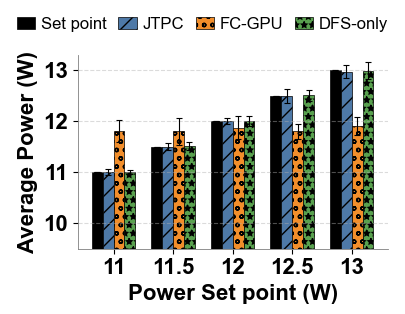

Saved plot to: figures\jetson_power_barplot.pdf
Saved plot to: figures\jetson_power_barplot.png


In [29]:
# LQR vs FC vs DFS Power Revision
# Single-degree-of-freedom slice:
# Fixed RTR setpoint = 0.90, sweep power setpoint.

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---------- FONT / STYLE ----------
plt.rcParams.update({
    "font.family": "Arial",
    "font.weight": "normal",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "axes.labelsize": 16,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ---------------- CONFIG ----------------
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 12

# Use adaptive FC-GPU log.
l_root = Path("02_regular_tests/logs/Full_LQR/hist_stereo_mm/")
f_root = Path("02_regular_tests/logs/Full_FC/hist_stereo_mm/")
d_root = Path("02_regular_tests/logs/Full_DFS/hist_stereo_mm/")

power = [11000, 11500, 12000, 12500, 13000]

# Fixed RTR point for power sweep.
FIXED_RTR = 0.70

save_path = Path("figures")

colors = ["black", "#4E79A7", "#F28E2B", "#59A14F"]
hatches = ["", "//", "oo", "**"]
names = ["Set point", "JTPC", "FC-GPU", "DFS-only"]

# ---------------- HELPERS ----------------
def read_data(filepath: Path):
    if not filepath.exists():
        print(f"Missing: {filepath}")
        return np.array([])
    try:
        return np.loadtxt(filepath)
    except Exception as e:
        print(f"Error reading {filepath}: {e}")
        return np.array([])


def safe_slice(arr):
    if arr.size == 0:
        return arr
    return arr[100:-1] if arr.size > 101 else arr


def find_setpoint_dir(root: Path, rtr_sp: float, power_sp: int):
    candidates = [
        root / f"setpoint_{power_sp}_{rtr_sp:.2f}_{rtr_sp:.2f}_{rtr_sp:.2f}",
        root / f"setpoint_{power_sp}_0.90_0.90_0.90",
        root / f"setpoint_{rtr_sp:.2f}",
    ]

    for c in candidates:
        if c.exists():
            return c

    print(f"No directory found for {root}, RTR={rtr_sp:.2f}, power={power_sp}")
    return None


def avg_power_for_case(root: Path, prefix: str, rtr_sp: float, power_sp: int):
    run_dir = find_setpoint_dir(root, rtr_sp, power_sp)

    if run_dir is None:
        return np.nan, np.nan

    power_reading = read_data(run_dir / f"{prefix}_finalpowervalues.txt")
    power_reading = safe_slice(power_reading)

    if power_reading.size == 0:
        return np.nan, np.nan

    return float(np.mean(power_reading)), float(np.std(power_reading))


# ---------------- COLLECT ----------------
lqr_group_means = []
lqr_group_stds = []

fc_group_means = []
fc_group_stds = []

dfs_group_means = []
dfs_group_stds = []

setpoint_group_means = []
setpoint_group_stds = []

for p_sp in power:
    print(f"Power setpoint: {p_sp / 1000:.1f}W, fixed RTR: {FIXED_RTR:.2f}")

    l_mean, l_std = avg_power_for_case(l_root, "LQR", FIXED_RTR, p_sp)
    f_mean, f_std = avg_power_for_case(f_root, "FC_GPU", FIXED_RTR, p_sp)
    d_mean, d_std = avg_power_for_case(d_root, "DFS", FIXED_RTR, p_sp)

    lqr_group_means.append(l_mean)
    lqr_group_stds.append(l_std)

    fc_group_means.append(f_mean)
    fc_group_stds.append(f_std)

    dfs_group_means.append(d_mean)
    dfs_group_stds.append(d_std)

    setpoint_group_means.append(float(p_sp))
    setpoint_group_stds.append(0.0)

    print("  JTPC:", l_mean)
    print("  FC-GPU:", f_mean)
    print("  DFS-only:", d_mean)

lqr_group_means = np.array(lqr_group_means)
lqr_group_stds = np.array(lqr_group_stds)

fc_group_means = np.array(fc_group_means)
fc_group_stds = np.array(fc_group_stds)

dfs_group_means = np.array(dfs_group_means)
dfs_group_stds = np.array(dfs_group_stds)

setpoint_group_means = np.array(setpoint_group_means)
setpoint_group_stds = np.array(setpoint_group_stds)

# ---------------- CONVERT mW TO W ----------------
lqr_group_means = lqr_group_means / 1000.0
lqr_group_stds = lqr_group_stds / 1000.0

fc_group_means = fc_group_means / 1000.0
fc_group_stds = fc_group_stds / 1000.0

dfs_group_means = dfs_group_means / 1000.0
dfs_group_stds = dfs_group_stds / 1000.0

setpoint_group_means = setpoint_group_means / 1000.0
setpoint_group_stds = setpoint_group_stds / 1000.0

power_w = [p / 1000.0 for p in power]

# ---------------- PLOT ----------------
fig, ax = plt.subplots(figsize=(4, 3))

x = np.arange(len(power_w)) * 0.82
bar_width = 0.15

all_means = [
    setpoint_group_means,
    lqr_group_means,
    fc_group_means,
    dfs_group_means,
]

all_stds = [
    setpoint_group_stds,
    lqr_group_stds,
    fc_group_stds,
    dfs_group_stds,
]

for i in range(4):
    ax.bar(
        x + (i - 1.5) * bar_width,
        all_means[i],
        bar_width,
        yerr=all_stds[i],
        color=colors[i],
        hatch=hatches[i],
        edgecolor="black",
        linewidth=0.5,
        label=names[i],
        error_kw=dict(
            elinewidth=0.8,
            capsize=2,
            capthick=0.8,
        ),
    )

ax.set_xlabel("Power Set point (W)", fontsize=LABEL_FONTSIZE, fontweight="bold")
ax.set_ylabel("Average Power (W)", fontsize=LABEL_FONTSIZE, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels([f"{p:g}" for p in power_w], fontweight="bold")

ax.grid(axis="y", linestyle="--", alpha=0.45)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("gray")
ax.spines["left"].set_linewidth(0.6)

ax.spines["bottom"].set_color("gray")
ax.spines["bottom"].set_linewidth(0.6)

handles, labels = ax.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.03),
    ncol=4,
    frameon=False,
    prop={"size": LEGEND_FONTSIZE},
    columnspacing=0.7,
    handlelength=1.1,
    handletextpad=0.35,
    borderaxespad=0.0,
)

ax.set_ylim([9.5, 13.3])
ax.set_yticks([10, 11, 12, 13])

plt.xticks(fontsize=TICK_FONTSIZE, fontweight="bold")
plt.yticks(fontsize=TICK_FONTSIZE, fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.93])

save_path.mkdir(exist_ok=True)

out_pdf = save_path / "jetson_power_barplot.pdf"
out_png = save_path / "jetson_power_barplot.png"

plt.savefig(out_pdf, dpi=300, bbox_inches="tight", format="pdf")
plt.savefig(out_png, dpi=300, bbox_inches="tight", format="png")

plt.show()

print("Saved plot to:", out_pdf)
print("Saved plot to:", out_png)

RTR setpoint: 0.70, fixed power: 11.0W
  JTPC: 0.7253700390070922
  FC-GPU: 0.700174342857143
  DFS-only: 15.988109705673757
RTR setpoint: 0.75, fixed power: 11.0W
  JTPC: 0.7573561914893616
  FC-GPU: 0.7488684861111112
  DFS-only: 16.190573803508773
RTR setpoint: 0.80, fixed power: 11.0W
  JTPC: 0.8003782280701754
  FC-GPU: 0.7986395578947368
  DFS-only: 16.446622238596493
RTR setpoint: 0.85, fixed power: 11.0W
  JTPC: 0.8500714113475175
  FC-GPU: 0.8484743859649121
  DFS-only: 11.62984971875
RTR setpoint: 0.90, fixed power: 11.0W
  JTPC: 0.8999604456140352
  FC-GPU: 0.898376101754386
  DFS-only: 14.485547542553194


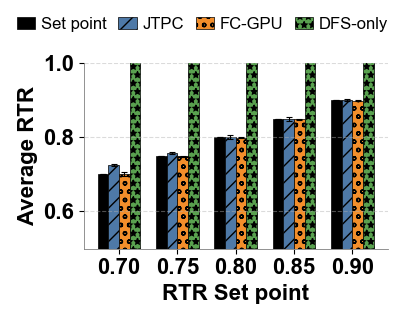

Saved plot to: figures\jetson_rtr_barplot_11W.pdf
Saved plot to: figures\jetson_rtr_barplot_11W.png


In [20]:
# LQR vs FC vs DFS RTR Revision
# Single-degree-of-freedom slice:
# Fixed power setpoint = 11W, sweep RTR setpoint.

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# ---------- FONT / STYLE ----------
plt.rcParams.update({
    "font.family": "Arial",
    "font.weight": "normal",
    "axes.labelweight": "bold",
    "axes.titleweight": "bold",
    "axes.titlesize": 16,
    "legend.fontsize": 12,
    "axes.labelsize": 16,
    "xtick.labelsize": 16,
    "ytick.labelsize": 16,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})

# ---------------- CONFIG ----------------
LABEL_FONTSIZE = 16
TICK_FONTSIZE = 16
LEGEND_FONTSIZE = 12

l_root = Path("02_regular_tests/logs/Full_LQR/hist_stereo_mm/")
f_root = Path("02_regular_tests/logs/Full_FC/hist_stereo_mm/")
d_root = Path("02_regular_tests/logs/Full_DFS/hist_stereo_mm/")

setpoints = [0.70, 0.75, 0.80, 0.85, 0.90]

# Fixed power point for RTR sweep.
FIXED_POWER = 11000  # 11W

save_path = Path("figures")

colors = ["black", "#4E79A7", "#F28E2B", "#59A14F"]
hatches = ["", "//", "oo", "**"]
names = ["Set point", "JTPC", "FC-GPU", "DFS-only"]

# ---------------- HELPERS ----------------
def read_data(filepath: Path):
    if not filepath.exists():
        print(f"Missing: {filepath}")
        return np.array([])
    try:
        return np.loadtxt(filepath)
    except Exception as e:
        print(f"Error reading {filepath}: {e}")
        return np.array([])


def safe_slice(arr):
    """
    Remove invalid zero padding/shutdown tail, then remove a small early transient.
    This avoids the old arr[100:-1] behavior, which can accidentally keep only zeros.
    """
    if arr.size == 0:
        return arr

    arr = arr[np.isfinite(arr)]
    arr = arr[arr > 0]

    if arr.size == 0:
        return arr

    # Drop early transient conservatively.
    start = min(20, max(0, arr.size // 5))
    return arr[start:]


def find_setpoint_dir(root: Path, rtr_sp: float, power_sp: int):
    candidates = [
        root / f"setpoint_{power_sp}_{rtr_sp:.2f}_{rtr_sp:.2f}_{rtr_sp:.2f}",
        root / f"setpoint_{rtr_sp:.2f}",
    ]

    for c in candidates:
        if c.exists():
            return c

    print(f"No directory found for {root}, RTR={rtr_sp:.2f}, power={power_sp}")
    return None


def avg_rtr_for_case(root: Path, prefix: str, rtr_sp: float, power_sp: int):
    run_dir = find_setpoint_dir(root, rtr_sp, power_sp)

    if run_dir is None:
        return np.nan, np.nan

    t1 = safe_slice(read_data(run_dir / f"{prefix}_t1_rtr.txt"))
    t2 = safe_slice(read_data(run_dir / f"{prefix}_t2_rtr.txt"))
    t3 = safe_slice(read_data(run_dir / f"{prefix}_t3_rtr.txt"))

    n = min(len(t1), len(t2), len(t3))

    if n == 0:
        return np.nan, np.nan

    avg_trace = (t1[:n] + t2[:n] + t3[:n]) / 3.0

    return float(np.mean(avg_trace)), float(np.std(avg_trace))


# ---------------- COLLECT ----------------
setpoint_group_means = []
setpoint_group_stds = []

lqr_group_means = []
lqr_group_stds = []

fc_group_means = []
fc_group_stds = []

dfs_group_means = []
dfs_group_stds = []

for rtr_sp in setpoints:
    print(f"RTR setpoint: {rtr_sp:.2f}, fixed power: {FIXED_POWER / 1000:.1f}W")

    l_mean, l_std = avg_rtr_for_case(l_root, "LQR", rtr_sp, FIXED_POWER)
    f_mean, f_std = avg_rtr_for_case(f_root, "FC_GPU", rtr_sp, FIXED_POWER)
    d_mean, d_std = avg_rtr_for_case(d_root, "DFS", rtr_sp, FIXED_POWER)

    setpoint_group_means.append(rtr_sp)
    setpoint_group_stds.append(0.0)

    lqr_group_means.append(l_mean)
    lqr_group_stds.append(l_std)

    fc_group_means.append(f_mean)
    fc_group_stds.append(f_std)

    dfs_group_means.append(d_mean)
    dfs_group_stds.append(d_std)

    print("  JTPC:", l_mean)
    print("  FC-GPU:", f_mean)
    print("  DFS-only:", d_mean)

setpoint_group_means = np.array(setpoint_group_means)
setpoint_group_stds = np.array(setpoint_group_stds)

lqr_group_means = np.array(lqr_group_means)
lqr_group_stds = np.array(lqr_group_stds)

fc_group_means = np.array(fc_group_means)
fc_group_stds = np.array(fc_group_stds)

dfs_group_means = np.array(dfs_group_means)
dfs_group_stds = np.array(dfs_group_stds)

# ---------------- PLOT ----------------
fig, ax = plt.subplots(figsize=(4, 3))

x = np.arange(len(setpoints)) * 0.82
bar_width = 0.15

all_means = [
    setpoint_group_means,
    lqr_group_means,
    fc_group_means,
    dfs_group_means,
]

all_stds = [
    setpoint_group_stds,
    lqr_group_stds,
    fc_group_stds,
    dfs_group_stds,
]

for i in range(4):
    ax.bar(
        x + (i - 1.5) * bar_width,
        all_means[i],
        bar_width,
        yerr=all_stds[i],
        color=colors[i],
        hatch=hatches[i],
        edgecolor="black",
        linewidth=0.5,
        label=names[i],
        error_kw=dict(
            elinewidth=0.8,
            capsize=2,
            capthick=0.8,
        ),
    )

ax.set_xlabel("RTR Set point", fontsize=LABEL_FONTSIZE, fontweight="bold")
ax.set_ylabel("Average RTR", fontsize=LABEL_FONTSIZE, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels([f"{sp:.2f}" for sp in setpoints], fontweight="bold")

ax.grid(axis="y", linestyle="--", alpha=0.45)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_color("gray")
ax.spines["left"].set_linewidth(0.6)

ax.spines["bottom"].set_color("gray")
ax.spines["bottom"].set_linewidth(0.6)

handles, labels = ax.get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.03),
    ncol=4,
    frameon=False,
    prop={"size": LEGEND_FONTSIZE},
    columnspacing=0.7,
    handlelength=1.1,
    handletextpad=0.35,
    borderaxespad=0.0,
)

# Diagnostic mode for 11W:
# If DFS explodes, this lets you see the real value instead of silently clipping it.
valid_means = np.concatenate([
    lqr_group_means[np.isfinite(lqr_group_means)],
    fc_group_means[np.isfinite(fc_group_means)],
    dfs_group_means[np.isfinite(dfs_group_means)],
    setpoint_group_means[np.isfinite(setpoint_group_means)],
])

if valid_means.size > 0:
    ymax = max(1.0, float(np.max(valid_means)) * 1.10)
    ax.set_ylim([0.5, 1])
else:
    ax.set_ylim([0.5, 1.0])

plt.xticks(fontsize=TICK_FONTSIZE, fontweight="bold")
plt.yticks(fontsize=TICK_FONTSIZE, fontweight="bold")

plt.tight_layout(rect=[0, 0, 1, 0.93])

save_path.mkdir(exist_ok=True)

out_pdf = save_path / "jetson_rtr_barplot_11W.pdf"
out_png = save_path / "jetson_rtr_barplot_11W.png"

plt.savefig(out_pdf, dpi=300, bbox_inches="tight", format="pdf")
plt.savefig(out_png, dpi=300, bbox_inches="tight", format="png")

plt.show()

print("Saved plot to:", out_pdf)
print("Saved plot to:", out_png)

In [34]:
from pathlib import Path
import numpy as np

ROOT = Path(r"C:\Users\tiare\Desktop\plot\main_temp")
POWER = 12500
RTR = 0.90

cases = {
    "FC-GPU": {
        "dir": ROOT / "FC" / "hist_stereo_mm" / f"setpoint_{POWER}_{RTR:.2f}_{RTR:.2f}_{RTR:.2f}",
        "prefix": "FC_GPU",
    },
    "JTPC": {
        "dir": ROOT / "JTPC" / "hist_stereo_mm" / f"setpoint_{POWER}_{RTR:.2f}_{RTR:.2f}_{RTR:.2f}",
        "prefix": "LQR",
    },
}

def read_arr(path):
    if not path.exists():
        print("MISSING:", path)
        return np.array([])
    x = np.loadtxt(path)
    x = x[np.isfinite(x)]
    x = x[x > 0]
    return x

def mean(x):
    return float(np.mean(x)) if x.size else np.nan

print("========== 12.5W ROOT-CAUSE CHECK ==========")

summary = {}

for method, cfg in cases.items():
    d = cfg["dir"]
    p = cfg["prefix"]

    print(f"\n===== {method} =====")
    print("dir:", d)

    power = read_arr(d / f"{p}_finalpowervalues.txt") / 1000.0
    freq = read_arr(d / f"{p}_finalfreqvalsvalues.txt")

    print(f"power mean W = {mean(power):.3f}")
    print(f"freq mean MHz = {mean(freq):.2f}")

    summary[method] = {
        "power": mean(power),
        "freq": mean(freq),
        "tasks": {}
    }

    for tid in [1, 2, 3]:
        exe = read_arr(d / f"{p}_t{tid}_exec.txt")
        per = read_arr(d / f"{p}_t{tid}_period.txt")
        rtr = read_arr(d / f"{p}_t{tid}_rtr.txt")

        n = min(len(exe), len(per), len(rtr))
        exe = exe[:n]
        per = per[:n]
        rtr = rtr[:n]

        pressure = exe / per

        print(f"\nT{tid}:")
        print(f"  exec mean ms      = {mean(exe):.3f}")
        print(f"  period mean ms    = {mean(per):.3f}")
        print(f"  RTR mean          = {mean(rtr):.3f}")
        print(f"  exec/period       = {mean(pressure):.3f}")

        summary[method]["tasks"][tid] = {
            "exec": mean(exe),
            "period": mean(per),
            "rtr": mean(rtr),
            "pressure": mean(pressure),
        }

print("\n========== DIRECT DIFFERENCE: JTPC - FC-GPU ==========")

for key in ["power", "freq"]:
    diff = summary["JTPC"][key] - summary["FC-GPU"][key]
    print(f"{key}: JTPC - FC-GPU = {diff:.3f}")

for tid in [1, 2, 3]:
    print(f"\nT{tid}:")
    for key in ["exec", "period", "rtr", "pressure"]:
        fc = summary["FC-GPU"]["tasks"][tid][key]
        jt = summary["JTPC"]["tasks"][tid][key]
        print(f"  {key}: FC={fc:.3f}, JTPC={jt:.3f}, diff={jt-fc:.3f}")

print("\n========== INTERPRETATION ==========")
print("If FC-GPU frequency is fixed near max and periods barely change, FC-GPU is not using power feedback.")
print("If JTPC changes frequency/periods to hit the power setpoint, JTPC is actively using power feedback.")
print("Similar average utility can hide different per-task allocations and different task-level pressure.")

========== 12.5W ROOT-CAUSE CHECK ==========

===== FC-GPU =====
dir: C:\Users\tiare\Desktop\plot\main_temp\FC\hist_stereo_mm\setpoint_12500_0.90_0.90_0.90
power mean W = 12.103
freq mean MHz = 1020.00

T1:
  exec mean ms      = 105.736
  period mean ms    = 132.575
  RTR mean          = 0.802
  exec/period       = 0.802

T2:
  exec mean ms      = 53.957
  period mean ms    = 61.672
  RTR mean          = 0.879
  exec/period       = 0.879

T3:
  exec mean ms      = 54.895
  period mean ms    = 57.436
  RTR mean          = 0.971
  exec/period       = 0.957

===== JTPC =====
dir: C:\Users\tiare\Desktop\plot\main_temp\JTPC\hist_stereo_mm\setpoint_12500_0.90_0.90_0.90
power mean W = 12.497
freq mean MHz = 989.95

T1:
  exec mean ms      = 109.243
  period mean ms    = 122.239
  RTR mean          = 0.895
  exec/period       = 0.895

T2:
  exec mean ms      = 55.732
  period mean ms    = 62.328
  RTR mean          = 0.895
  exec/period       = 0.895

T3:
  exec mean ms      = 56.216
  period 